# SDF-YOLO v2 on NEU-DET (local GPU)

NEU-DET: 6 classes (crazing, inclusion, patches, pitted_surface, rolled-in_scale, scratches), 200×200 native, split 1260 / 180 / 360. The classes are balanced, so repeat-factor sampling has no effect here.

This notebook trains **SDF-YOLO-s** and the same-protocol baselines (**YOLO11s**, optionally **YOLOv8s**) on the same data, split and settings, then evaluates each one **once on the TEST split**. The metrics are mAP50, mAP50-95, F1, P, R, GFLOPs, Params and FPS, plus per-class AP50.

Runs on this machine's **NVIDIA RTX 3060**. Task Manager may list it as "GPU 1", but CUDA calls it device **`0`**. Open the notebook from this folder (next to `train.py`) and press **Run All**: training starts directly, same as the Colab commands (`train.py` defaults: 200 epochs, batch 32, imgsz 640, cache ram).

Runs go **one at a time** on the GPU. If another `train.py` (e.g. from the other notebook) is already training, this one prints *waiting in queue* and starts by itself when that run ends. Running two at once on the 12 GB card made each iteration take ~60 s and crashed with `illegal memory access`.

## 1. Setup

In [2]:
import sys, shutil
from pathlib import Path

DATASET = "neu"
PY = sys.executable   # train.py runs with the same Python as this kernel
PROJECT_DIR = Path.cwd()
assert (PROJECT_DIR / "train.py").exists(), f"open this notebook from the folder containing train.py (cwd={PROJECT_DIR})"
!"{PY}" -c "import torch, ultralytics; assert torch.cuda.is_available(), 'CUDA not available'; print('torch', torch.__version__, '| ultralytics', ultralytics.__version__, '|', torch.cuda.get_device_name(0))"
!nvidia-smi --query-gpu=name,memory.used,memory.total --format=csv


torch 2.11.0+cu128 | ultralytics 8.3.174 | NVIDIA GeForce RTX 3060
torch 2.11.0+cu128 | ultralytics 8.3.174 | NVIDIA GeForce RTX 3060
name, memory.used [MiB], memory.total [MiB]
NVIDIA GeForce RTX 3060, 9835 MiB, 12288 MiB


In [3]:
import os, re, codecs, subprocess
from IPython.display import display

def train(args):
    """Run train.py and stream its output live. IPython's `!` on Windows only prints
    once the process has exited, so a 200-epoch run would stay blank for hours
    (Colab runs on Linux, where `!` streams). Progress bars update in place.
    Stopping this cell (Interrupt) also stops the training process."""
    env = {**os.environ, "PYTHONUNBUFFERED": "1", "PYTHONIOENCODING": "utf-8"}
    p = subprocess.Popen([PY, "-u", "train.py", *args.split()], cwd=PROJECT_DIR, env=env,
                         stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
    dec = codecs.getincrementaldecoder("utf-8")(errors="replace")
    buf, bar = "", None   # bar: display handle of the progress line redrawn with carriage returns
    try:
        while chunk := p.stdout.read1(4096):
            buf += dec.decode(chunk)
            *segs, buf = re.split(r"(\r\n|\r|\n)", buf) if buf else [""]
            for seg, sep in zip(segs[::2], segs[1::2]):
                if sep == "\r":                      # progress bar redraw
                    if seg.strip():
                        if bar is None:
                            bar = display({"text/plain": seg}, raw=True, display_id=True)
                        else:
                            bar.update({"text/plain": seg}, raw=True)
                elif bar is not None:                # bar finished: freeze its last state
                    if seg.strip():
                        bar.update({"text/plain": seg}, raw=True)
                    bar = None
                else:
                    print(seg, flush=True)
        if buf.strip():
            print(buf)
        rc = p.wait()
    except KeyboardInterrupt:
        p.kill()
        p.wait()
        print("training stopped")
        raise
    if rc:
        raise RuntimeError(f"train.py exited with code {rc} -- see the output above")


## 2. Dataset check

In [4]:
EXPECTED = {'train': 1260, 'val': 180, 'test': 360}
root = PROJECT_DIR / "datasets" / DATASET
for split, n in EXPECTED.items():
    imgs = len(list((root / "images" / split).glob("*.jpg")))
    lbls = len(list((root / "labels" / split).glob("*.txt")))
    print(f"{split:<5} images={imgs:<5} labels={lbls:<5} expected={n}")
    assert imgs == n, f"{split}: expected {n} images, found {imgs}"
print("dataset OK")

train images=1260  labels=1260  expected=1260
val   images=180   labels=180   expected=180
test  images=360   labels=360   expected=360
dataset OK


If you hit CUDA out of memory add `--batch 16`; if RAM runs out add `--cache disk`.

## 3. Train SDF-YOLO-s

Always train through `train.py`, never by importing it. That way `CAA` pickles as `__main__.CAA` and `best.pt` stays loadable elsewhere.

In [ ]:
train(f"--data {DATASET} --model sdf")

GPU: NVIDIA GeForce RTX 3060
torch 2.11.0+cu128 | ultralytics 8.3.174

######################################################################
# neu_sdf_s_ch_sppf_e300
######################################################################
repeat-factor sampling: {'images': 1260, 'after_rfs': 1260, 'repeat_per_class': {0: 1.0, 1: 1.0, 2: 1.0, 3: 1.0, 4: 1.0, 5: 1.0}}
WARNING no model scale passed. Assuming scale='s'.
Transferred 295/550 items from pretrained weights
COCO Detect head: transferred 115/121 tensors (model.23 -> model.33)
New https://pypi.org/project/ultralytics/8.4.170 available  Update with 'pip install -U ultralytics'
Ultralytics 8.3.174  Python-3.12.10 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
engine\trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=ram, cfg=None, classes=None, close_mosaic=20, cls=0.5, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=C:\Users

train: Scanning C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\datasets\neu\labels\train.cache... 1260 images, 0 backgrounds, 0 corrupt: 100%|██████████| 1260/1260 [00:00<?, ?it/s]

train: C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\datasets\neu\images\train\crazing_120.jpg: 1 duplicate labels removed
train: C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\datasets\neu\images\train\inclusion_62.jpg: 1 duplicate labels removed
WARNING cache='ram' may produce non-deterministic training results. Consider cache='disk' as a deterministic alternative if your disk space allows.


train: Caching images (1.4GB RAM): 100%|██████████| 1260/1260 [00:00<00:00, 2197.37it/s]

albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', num_output_channels=3), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))
val: Fast image access  (ping: 0.10.0 ms, read: 44.112.4 MB/s, size: 18.7 KB)


...

Plotting labels to C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\runs\neu_sdf_s_ch_sppf_e300\labels.jpg... 
optimizer: 'optimizer=auto' found, ignoring 'lr0=0.01' and 'momentum=0.937' and determining best 'optimizer', 'lr0' and 'momentum' automatically... 
optimizer: AdamW(lr=0.001, momentum=0.9) with parameter groups 87 weight(decay=0.0), 106 weight(decay=0.0005), 96 bias(decay=0.0)
Image sizes 640 train, 640 val
Using 2 dataloader workers
Logging results to C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\runs\neu_sdf_s_ch_sppf_e300
Starting training for 300 epochs...

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


      1/300      9.83G      2.804      4.479      2.653         46        640: 100%|██████████| 40/40 [34:37<00:00, 51.93s/it]

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 3/3 [03:16<00:00, 65.57s/it]

                   all        180        423     0.0296       0.23     0.0533     0.0146

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


      2/300      9.76G      1.867      2.209      1.867         40        640: 100%|██████████| 40/40 [43:30<00:00, 65.25s/it]

## 4. Baseline: YOLO11s (same data, split and settings)

In [ ]:
train(f"--data {DATASET} --model yolo11s.pt")


GPU: NVIDIA GeForce RTX 3060
torch 2.11.0+cu128 | ultralytics 8.3.174
repeat-factor sampling: {'images': 1260, 'after_rfs': 1260, 'repeat_per_class': {0: 1.0, 1: 1.0, 2: 1.0, 3: 1.0, 4: 1.0, 5: 1.0}}
New https://pypi.org/project/ultralytics/8.4.165 available  Update with 'pip install -U ultralytics'
Ultralytics 8.3.174  Python-3.12.10 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
engine\trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=ram, cfg=None, classes=None, close_mosaic=20, cls=0.5, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\datasets\neu\data_neu_yolo11s.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=200, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_

train: Scanning C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\datasets\neu\labels\train.cache... 1260 images, 0 backgrounds, 0 corrupt: 100%|██████████| 1260/1260 [00:00<?, ?it/s]

train: C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\datasets\neu\images\train\crazing_120.jpg: 1 duplicate labels removed
train: C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\datasets\neu\images\train\inclusion_62.jpg: 1 duplicate labels removed
WARNING cache='ram' may produce non-deterministic training results. Consider cache='disk' as a deterministic alternative if your disk space allows.


train: Caching images (1.4GB RAM): 100%|██████████| 1260/1260 [00:00<00:00, 4118.68it/s]

val: Fast image access  (ping: 0.10.0 ms, read: 32.217.7 MB/s, size: 18.5 KB)


...

                   all        360        866        0.7      0.758      0.763       0.43
               crazing         60        134      0.503      0.469       0.42      0.152
             inclusion         80        223      0.769      0.794      0.835      0.444
               patches         68        180      0.836      0.861      0.907      0.607
        pitted_surface         60         84      0.761      0.845      0.889      0.534
       rolled-in_scale         60        137      0.579      0.672      0.622      0.256
             scratches         60        108      0.755      0.907      0.902      0.587
Speed: 0.5ms preprocess, 6.3ms inference, 0.0ms loss, 1.4ms postprocess per image
Results saved to C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\runs\neu_yolo11s_test
Ultralytics 8.3.174  Python-3.12.10 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
val: Fast image access  (ping: 0.00.0 ms, read: 129.562.8 MB/s, size: 11.6 KB)


val: Scanning C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\datasets\neu\labels\test.cache... 360 images, 0 backgrounds, 0 corrupt: 100%|██████████| 360/360 [00:00<?, ?it/s]

val: C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\datasets\neu\images\test\patches_198.jpg: 1 duplicate labels removed


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 360/360 [00:06<00:00, 57.54it/s]

                   all        360        866        0.7      0.758      0.763       0.43
Speed: 0.4ms preprocess, 13.5ms inference, 0.0ms loss, 1.6ms postprocess per image

yolo11s on neu -- TEST split
  mAP50      76.26
  mAP50_95   43.01
  F1         72.69
  GFLOPs     21.3
  Params_M   9.42
  FPS_bs1    64.4
  per-class AP50: {'crazing': 42.0, 'inclusion': 83.5, 'patches': 90.7, 'pitted_surface': 88.9, 'rolled-in_scale': 62.2, 'scratches': 90.2}
  train time: 60.2 min | summary -> C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\runs\neu_yolo11s\summary.json


## 5. (Optional) Baseline: YOLOv8s

In [ ]:
train(f"--data {DATASET} --model yolov8s.pt")


GPU: NVIDIA GeForce RTX 3060
torch 2.11.0+cu128 | ultralytics 8.3.174
repeat-factor sampling: {'images': 1260, 'after_rfs': 1260, 'repeat_per_class': {0: 1.0, 1: 1.0, 2: 1.0, 3: 1.0, 4: 1.0, 5: 1.0}}
Ultralytics 8.3.174  Python-3.12.10 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
engine\trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=ram, cfg=None, classes=None, close_mosaic=20, cls=0.5, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\datasets\neu\data_neu_yolov8s.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=200, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, l

train: Scanning C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\datasets\neu\labels\train.cache... 1260 images, 0 backgrounds, 0 corrupt: 100%|██████████| 1260/1260 [00:00<?, ?it/s]

train: C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\datasets\neu\images\train\crazing_120.jpg: 1 duplicate labels removed
train: C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\datasets\neu\images\train\inclusion_62.jpg: 1 duplicate labels removed
WARNING cache='ram' may produce non-deterministic training results. Consider cache='disk' as a deterministic alternative if your disk space allows.


train: Caching images (1.4GB RAM): 100%|██████████| 1260/1260 [00:00<00:00, 3803.29it/s]

val: Fast image access  (ping: 0.10.0 ms, read: 34.19.9 MB/s, size: 18.5 KB)


...

                   all        360        866      0.755      0.739      0.778      0.439
               crazing         60        134      0.559      0.485      0.483      0.172
             inclusion         80        223      0.796      0.769      0.836      0.446
               patches         68        180      0.858      0.856      0.882      0.578
        pitted_surface         60         84      0.846      0.833      0.867      0.584
       rolled-in_scale         60        137      0.679      0.586      0.661      0.295
             scratches         60        108      0.795      0.907      0.936      0.559
Speed: 0.5ms preprocess, 6.5ms inference, 0.0ms loss, 1.3ms postprocess per image
Results saved to C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\runs\neu_yolov8s_test
Ultralytics 8.3.174  Python-3.12.10 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
val: Fast image access  (ping: 0.00.0 ms, read: 135.869.4 MB/s, size: 11.6 KB)


val: Scanning C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\datasets\neu\labels\test.cache... 360 images, 0 backgrounds, 0 corrupt: 100%|██████████| 360/360 [00:00<?, ?it/s]

val: C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\datasets\neu\images\test\patches_198.jpg: 1 duplicate labels removed


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 360/360 [00:04<00:00, 72.47it/s]

                   all        360        866      0.755       0.74      0.778      0.439
Speed: 0.4ms preprocess, 10.1ms inference, 0.0ms loss, 1.6ms postprocess per image

yolov8s on neu -- TEST split
  mAP50      77.76
  mAP75      41.46
  mAP50_95   43.9
  F1         74.58
  GFLOPs     28.4
  Params_M   11.13
  FPS_bs1    83.3
  per_class_AP50: {'crazing': 48.3, 'inclusion': 83.6, 'patches': 88.2, 'pitted_surface': 86.7, 'rolled-in_scale': 66.1, 'scratches': 93.6}
  per_class_AP75: {'crazing': 6.5, 'inclusion': 40.8, 'patches': 66.6, 'pitted_surface': 59.0, 'rolled-in_scale': 21.9, 'scratches': 54.0}
  per_class_AP50_95: {'crazing': 17.2, 'inclusion': 44.6, 'patches': 57.8, 'pitted_surface': 58.4, 'rolled-in_scale': 29.5, 'scratches': 55.9}
  train time: 59.0 min | summary -> C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\runs\neu_yolov8s\summary.json


## 6. Baseline: YOLO11n (nano)

In [ ]:
train(f"--data {DATASET} --model yolo11n.pt")

GPU: NVIDIA GeForce RTX 3060
torch 2.11.0+cu128 | ultralytics 8.3.174
repeat-factor sampling: {'images': 1260, 'after_rfs': 1260, 'repeat_per_class': {0: 1.0, 1: 1.0, 2: 1.0, 3: 1.0, 4: 1.0, 5: 1.0}}
New https://pypi.org/project/ultralytics/8.4.165 available  Update with 'pip install -U ultralytics'
Ultralytics 8.3.174  Python-3.12.10 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
engine\trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=ram, cfg=None, classes=None, close_mosaic=20, cls=0.5, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\datasets\neu\data_neu_yolo11n.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=200, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_

train: Scanning C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\datasets\neu\labels\train.cache... 1260 images, 0 backgrounds, 0 corrupt: 100%|██████████| 1260/1260 [00:00<?, ?it/s]

train: C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\datasets\neu\images\train\crazing_120.jpg: 1 duplicate labels removed
train: C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\datasets\neu\images\train\inclusion_62.jpg: 1 duplicate labels removed
WARNING cache='ram' may produce non-deterministic training results. Consider cache='disk' as a deterministic alternative if your disk space allows.


train: Caching images (1.4GB RAM): 100%|██████████| 1260/1260 [00:00<00:00, 4436.56it/s]

val: Fast image access  (ping: 0.10.0 ms, read: 102.857.2 MB/s, size: 18.5 KB)


...

                   all        360        866      0.755      0.723      0.768      0.439
               crazing         60        134      0.533      0.373      0.408      0.142
             inclusion         80        223      0.785      0.772      0.837       0.47
               patches         68        180      0.883      0.878      0.918      0.607
        pitted_surface         60         84      0.859       0.81      0.876      0.562
       rolled-in_scale         60        137      0.675      0.607      0.665      0.297
             scratches         60        108      0.796      0.901      0.905      0.553
Speed: 0.5ms preprocess, 3.4ms inference, 0.0ms loss, 1.6ms postprocess per image
Results saved to C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\runs\neu_yolo11n_test
Ultralytics 8.3.174  Python-3.12.10 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
val: Fast image access  (ping: 0.00.0 ms, read: 137.569.0 MB/s, size: 11.6 KB)


val: Scanning C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\datasets\neu\labels\test.cache... 360 images, 0 backgrounds, 0 corrupt: 100%|██████████| 360/360 [00:00<?, ?it/s]

val: C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\datasets\neu\images\test\patches_198.jpg: 1 duplicate labels removed


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 360/360 [00:06<00:00, 59.26it/s]

                   all        360        866      0.755      0.724      0.768      0.438
Speed: 0.4ms preprocess, 13.1ms inference, 0.0ms loss, 1.6ms postprocess per image

yolo11n on neu -- TEST split
  mAP50      76.82
  mAP75      41.87
  mAP50_95   43.86
  F1         73.59
  GFLOPs     6.3
  Params_M   2.58
  FPS_bs1    66.3
  per_class_AP50: {'crazing': 40.8, 'inclusion': 83.7, 'patches': 91.8, 'pitted_surface': 87.6, 'rolled-in_scale': 66.5, 'scratches': 90.5}
  per_class_AP75: {'crazing': 4.4, 'inclusion': 44.8, 'patches': 71.3, 'pitted_surface': 52.9, 'rolled-in_scale': 20.5, 'scratches': 57.4}
  per_class_AP50_95: {'crazing': 14.2, 'inclusion': 47.0, 'patches': 60.7, 'pitted_surface': 56.2, 'rolled-in_scale': 29.7, 'scratches': 55.3}
  train time: 37.7 min | summary -> C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\runs\neu_yolo11n\summary.json


## 7. Baseline: YOLOv5s

In [ ]:
train(f"--data {DATASET} --model yolov5su.pt")

GPU: NVIDIA GeForce RTX 3060
torch 2.11.0+cu128 | ultralytics 8.3.174
repeat-factor sampling: {'images': 1260, 'after_rfs': 1260, 'repeat_per_class': {0: 1.0, 1: 1.0, 2: 1.0, 3: 1.0, 4: 1.0, 5: 1.0}}
Ultralytics 8.3.174  Python-3.12.10 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
engine\trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=ram, cfg=None, classes=None, close_mosaic=20, cls=0.5, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\datasets\neu\neu_yolov5su_data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=200, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, 

train: Scanning C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\datasets\neu\labels\train.cache... 1260 images, 0 backgrounds, 0 corrupt: 100%|██████████| 1260/1260 [00:00<?, ?it/s]

train: C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\datasets\neu\images\train\crazing_120.jpg: 1 duplicate labels removed
train: C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\datasets\neu\images\train\inclusion_62.jpg: 1 duplicate labels removed
WARNING cache='ram' may produce non-deterministic training results. Consider cache='disk' as a deterministic alternative if your disk space allows.


train: Caching images (1.4GB RAM): 100%|██████████| 1260/1260 [00:00<00:00, 4026.88it/s]

val: Fast image access  (ping: 0.10.0 ms, read: 39.214.6 MB/s, size: 18.5 KB)


...

                   all        360        866      0.713      0.728      0.747      0.432
               crazing         60        134      0.478      0.403        0.4      0.145
             inclusion         80        223      0.806      0.785      0.826      0.437
               patches         68        180      0.869      0.867      0.905      0.611
        pitted_surface         60         84      0.756      0.798      0.838      0.568
       rolled-in_scale         60        137        0.6       0.62      0.598      0.274
             scratches         60        108      0.766      0.898      0.914      0.556
Speed: 0.4ms preprocess, 6.2ms inference, 0.0ms loss, 1.5ms postprocess per image
Results saved to C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\runs\neu_yolov5su_test
Ultralytics 8.3.174  Python-3.12.10 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
val: Fast image access  (ping: 0.00.0 ms, read: 131.570.1 MB/s, size: 11.6 KB)


val: Scanning C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\datasets\neu\labels\test.cache... 360 images, 0 backgrounds, 0 corrupt: 100%|██████████| 360/360 [00:00<?, ?it/s]

val: C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\datasets\neu\images\test\patches_198.jpg: 1 duplicate labels removed


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 360/360 [00:06<00:00, 59.43it/s]

                   all        360        866      0.713      0.728      0.747      0.432
Speed: 0.4ms preprocess, 12.6ms inference, 0.0ms loss, 1.8ms postprocess per image

yolov5su on neu -- TEST split
  mAP50      74.72
  mAP75      43.7
  mAP50_95   43.2
  F1         71.9
  GFLOPs     23.8
  Params_M   9.11
  FPS_bs1    67.6
  per_class_AP50: {'crazing': 40.0, 'inclusion': 82.6, 'patches': 90.5, 'pitted_surface': 83.8, 'rolled-in_scale': 59.8, 'scratches': 91.4}
  per_class_AP75: {'crazing': 8.1, 'inclusion': 44.8, 'patches': 71.2, 'pitted_surface': 59.6, 'rolled-in_scale': 19.4, 'scratches': 59.1}
  per_class_AP50_95: {'crazing': 14.5, 'inclusion': 43.7, 'patches': 61.1, 'pitted_surface': 56.8, 'rolled-in_scale': 27.4, 'scratches': 55.6}
  train time: 55.8 min | summary -> C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\runs\neu_yolov5su\summary.json


## 8. Baseline: YOLOv9s

In [ ]:
train(f"--data {DATASET} --model yolov9s.pt")

GPU: NVIDIA GeForce RTX 3060
another train.py run is using the GPU -- waiting in queue, this run starts automatically when it finishes...
GPU free, starting.
torch 2.11.0+cu128 | ultralytics 8.3.174

######################################################################
# neu_yolov9s
######################################################################
repeat-factor sampling: {'images': 1260, 'after_rfs': 1260, 'repeat_per_class': {0: 1.0, 1: 1.0, 2: 1.0, 3: 1.0, 4: 1.0, 5: 1.0}}
New https://pypi.org/project/ultralytics/8.4.166 available  Update with 'pip install -U ultralytics'
Ultralytics 8.3.174  Python-3.12.10 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
engine\trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=ram, cfg=None, classes=None, close_mosaic=20, cls=0.5, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_y

train: Scanning C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\datasets\neu\labels\train.cache... 1260 images, 0 backgrounds, 0 corrupt: 100%|██████████| 1260/1260 [00:00<?, ?it/s]

train: C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\datasets\neu\images\train\crazing_120.jpg: 1 duplicate labels removed
train: C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\datasets\neu\images\train\inclusion_62.jpg: 1 duplicate labels removed
WARNING cache='ram' may produce non-deterministic training results. Consider cache='disk' as a deterministic alternative if your disk space allows.


train: Caching images (1.4GB RAM): 100%|██████████| 1260/1260 [00:00<00:00, 4126.43it/s]

val: Fast image access  (ping: 0.20.1 ms, read: 38.810.9 MB/s, size: 18.5 KB)


...

                   all        360        866      0.763      0.713      0.764       0.45
               crazing         60        134      0.503      0.392      0.411      0.173
             inclusion         80        223      0.829      0.762      0.861      0.478
               patches         68        180      0.894       0.85      0.891      0.622
        pitted_surface         60         84      0.848      0.798      0.885      0.574
       rolled-in_scale         60        137      0.641      0.569      0.606      0.262
             scratches         60        108      0.862      0.907      0.931      0.591
Speed: 0.5ms preprocess, 7.6ms inference, 0.0ms loss, 1.2ms postprocess per image
Results saved to C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\runs\neu_yolov9s_test
Ultralytics 8.3.174  Python-3.12.10 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
val: Fast image access  (ping: 0.00.0 ms, read: 129.969.6 MB/s, size: 11.6 KB)


val: Scanning C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\datasets\neu\labels\test.cache... 360 images, 0 backgrounds, 0 corrupt: 100%|██████████| 360/360 [00:00<?, ?it/s]

val: C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\datasets\neu\images\test\patches_198.jpg: 1 duplicate labels removed


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 360/360 [00:10<00:00, 33.52it/s]

                   all        360        866      0.762      0.712      0.764       0.45
Speed: 0.4ms preprocess, 26.0ms inference, 0.0ms loss, 1.6ms postprocess per image

YOLOv9s on neu -- TEST split
  mAP50      76.41
  mAP75      43.66
  mAP50_95   45.0
  F1         73.58
  GFLOPs     26.7
  Params_M   7.17
  FPS_bs1    35.7
  per_class_AP50: {'crazing': 41.1, 'inclusion': 86.1, 'patches': 89.1, 'pitted_surface': 88.5, 'rolled-in_scale': 60.6, 'scratches': 93.1}
  per_class_AP75: {'crazing': 9.8, 'inclusion': 47.1, 'patches': 69.3, 'pitted_surface': 56.5, 'rolled-in_scale': 16.9, 'scratches': 62.2}
  per_class_AP50_95: {'crazing': 17.3, 'inclusion': 47.8, 'patches': 62.2, 'pitted_surface': 57.4, 'rolled-in_scale': 26.2, 'scratches': 59.1}
  train time: 84.9 min | summary -> C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\runs\neu_yolov9s\summary.json


## 9. Baseline: YOLOv10s

In [ ]:
train(f"--data {DATASET} --model yolov10s.pt")

GPU: NVIDIA GeForce RTX 3060
torch 2.11.0+cu128 | ultralytics 8.3.174

######################################################################
# neu_yolov10s
######################################################################
repeat-factor sampling: {'images': 1260, 'after_rfs': 1260, 'repeat_per_class': {0: 1.0, 1: 1.0, 2: 1.0, 3: 1.0, 4: 1.0, 5: 1.0}}
New https://pypi.org/project/ultralytics/8.4.166 available  Update with 'pip install -U ultralytics'
Ultralytics 8.3.174  Python-3.12.10 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
engine\trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=ram, cfg=None, classes=None, close_mosaic=20, cls=0.5, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\datasets\neu\neu_yolov10s_data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=

train: Scanning C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\datasets\neu\labels\train.cache... 1260 images, 0 backgrounds, 0 corrupt: 100%|██████████| 1260/1260 [00:00<?, ?it/s]

train: C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\datasets\neu\images\train\crazing_120.jpg: 1 duplicate labels removed
train: C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\datasets\neu\images\train\inclusion_62.jpg: 1 duplicate labels removed
WARNING cache='ram' may produce non-deterministic training results. Consider cache='disk' as a deterministic alternative if your disk space allows.


train: Caching images (1.4GB RAM): 100%|██████████| 1260/1260 [00:00<00:00, 4229.49it/s]

val: Fast image access  (ping: 0.10.0 ms, read: 36.08.1 MB/s, size: 18.5 KB)


...

                   all        360        866      0.744      0.727      0.765      0.432
               crazing         60        134      0.466      0.433      0.437       0.15
             inclusion         80        223       0.83      0.768      0.845      0.456
               patches         68        180      0.901      0.861      0.913        0.6
        pitted_surface         60         84       0.74       0.81      0.856      0.552
       rolled-in_scale         60        137      0.683      0.657       0.65      0.283
             scratches         60        108      0.843      0.833       0.89      0.551
Speed: 0.4ms preprocess, 6.6ms inference, 0.0ms loss, 0.2ms postprocess per image
Results saved to C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\runs\neu_yolov10s_test
Ultralytics 8.3.174  Python-3.12.10 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
val: Fast image access  (ping: 0.00.0 ms, read: 133.569.0 MB/s, size: 11.6 KB)


val: Scanning C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\datasets\neu\labels\test.cache... 360 images, 0 backgrounds, 0 corrupt: 100%|██████████| 360/360 [00:00<?, ?it/s]

val: C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\datasets\neu\images\test\patches_198.jpg: 1 duplicate labels removed


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 360/360 [00:06<00:00, 53.54it/s]

                   all        360        866      0.743      0.727      0.765      0.432
Speed: 0.4ms preprocess, 15.7ms inference, 0.0ms loss, 0.3ms postprocess per image

YOLOv10s on neu -- TEST split
  mAP50      76.51
  mAP75      42.48
  mAP50_95   43.2
  F1         73.47
  GFLOPs     21.4
  Params_M   7.22
  FPS_bs1    60.9
  per_class_AP50: {'crazing': 43.7, 'inclusion': 84.5, 'patches': 91.3, 'pitted_surface': 85.6, 'rolled-in_scale': 65.0, 'scratches': 89.0}
  per_class_AP75: {'crazing': 7.2, 'inclusion': 45.2, 'patches': 66.7, 'pitted_surface': 56.4, 'rolled-in_scale': 20.0, 'scratches': 59.3}
  per_class_AP50_95: {'crazing': 15.0, 'inclusion': 45.6, 'patches': 60.0, 'pitted_surface': 55.2, 'rolled-in_scale': 28.3, 'scratches': 55.1}
  train time: 73.8 min | summary -> C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\runs\neu_yolov10s\summary.json


## 10. Baseline: YOLO12s

In [ ]:
train(f"--data {DATASET} --model yolo12s.pt")

GPU: NVIDIA GeForce RTX 3060
torch 2.11.0+cu128 | ultralytics 8.3.174

######################################################################
# neu_yolo12s
######################################################################
repeat-factor sampling: {'images': 1260, 'after_rfs': 1260, 'repeat_per_class': {0: 1.0, 1: 1.0, 2: 1.0, 3: 1.0, 4: 1.0, 5: 1.0}}
New https://pypi.org/project/ultralytics/8.4.166 available  Update with 'pip install -U ultralytics'
Ultralytics 8.3.174  Python-3.12.10 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
engine\trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=ram, cfg=None, classes=None, close_mosaic=20, cls=0.5, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\datasets\neu\neu_yolo12s_data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=Fa

train: Scanning C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\datasets\neu\labels\train.cache... 1260 images, 0 backgrounds, 0 corrupt: 100%|██████████| 1260/1260 [00:00<?, ?it/s]

train: C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\datasets\neu\images\train\crazing_120.jpg: 1 duplicate labels removed
train: C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\datasets\neu\images\train\inclusion_62.jpg: 1 duplicate labels removed
WARNING cache='ram' may produce non-deterministic training results. Consider cache='disk' as a deterministic alternative if your disk space allows.


train: Caching images (1.4GB RAM): 100%|██████████| 1260/1260 [00:00<00:00, 4237.47it/s]

val: Fast image access  (ping: 0.10.0 ms, read: 39.310.7 MB/s, size: 18.5 KB)


...

                   all        360        866      0.728      0.701      0.741      0.427
               crazing         60        134      0.467      0.328      0.386      0.143
             inclusion         80        223      0.802      0.749      0.811      0.466
               patches         68        180      0.833      0.856      0.893      0.588
        pitted_surface         60         84      0.852       0.75      0.835      0.554
       rolled-in_scale         60        137      0.621      0.586      0.608      0.247
             scratches         60        108      0.794      0.935      0.915      0.564
Speed: 0.4ms preprocess, 9.0ms inference, 0.0ms loss, 1.1ms postprocess per image
Results saved to C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\runs\neu_yolo12s_test
Ultralytics 8.3.174  Python-3.12.10 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 3060, 12288MiB)
val: Fast image access  (ping: 0.00.0 ms, read: 116.741.3 MB/s, size: 11.6 KB)


val: Scanning C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\datasets\neu\labels\test.cache... 360 images, 0 backgrounds, 0 corrupt: 100%|██████████| 360/360 [00:00<?, ?it/s]

val: C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\datasets\neu\images\test\patches_198.jpg: 1 duplicate labels removed


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 360/360 [00:08<00:00, 43.94it/s]

                   all        360        866      0.728      0.701      0.742      0.427
Speed: 0.4ms preprocess, 18.9ms inference, 0.0ms loss, 1.6ms postprocess per image

YOLO12s on neu -- TEST split
  mAP50      74.14
  mAP75      41.7
  mAP50_95   42.7
  F1         71.06
  GFLOPs     21.2
  Params_M   9.23
  FPS_bs1    47.8
  per_class_AP50: {'crazing': 38.6, 'inclusion': 81.1, 'patches': 89.3, 'pitted_surface': 83.5, 'rolled-in_scale': 60.8, 'scratches': 91.5}
  per_class_AP75: {'crazing': 6.5, 'inclusion': 49.9, 'patches': 65.4, 'pitted_surface': 54.7, 'rolled-in_scale': 13.4, 'scratches': 60.3}
  per_class_AP50_95: {'crazing': 14.3, 'inclusion': 46.6, 'patches': 58.8, 'pitted_surface': 55.4, 'rolled-in_scale': 24.7, 'scratches': 56.4}
  train time: 95.8 min | summary -> C:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\runs\neu_yolo12s\summary.json


## 11. Results (TEST split)

In [ ]:
import json
import pandas as pd
from IPython.display import Image, display

table = Path("runs/results_table.csv")
df = pd.read_csv(table)
df = df[df.dataset == DATASET].drop_duplicates("run", keep="last")
display(df.set_index("run"))

per_class = {}
for run in df.run:
    s = Path("runs", run, "summary.json")
    if s.exists():
        per_class[run] = json.loads(s.read_text())["test_split"]["per_class_AP50"]
if per_class:
    print("per-class AP50 (test)")
    display(pd.DataFrame(per_class))

,dataset,model,mAP50,mAP75,mAP50_95,F1,Precision,Recall,GFLOPs,Params_M,FPS_bs1,imgsz,epochs,rfs_threshold
run,,,,,,,,,,,,,,
neu_sdf_s,neu,SDF-YOLO-s,76.04,40.38,42.63,72.46,74.12,71.52,28.6,13.05,46.7,640,200,0.1
neu_yolo11n,neu,YOLO11n,76.82,41.87,43.86,73.59,75.51,72.33,6.3,2.58,66.3,640,200,0.1
neu_yolo11s,neu,YOLO11s,76.26,42.38,43.01,72.69,70.05,75.79,21.3,9.42,64.4,640,200,0.1
neu_yolo12s,neu,YOLO12s,74.14,41.70,42.70,71.06,72.80,70.06,21.2,9.23,47.8,640,200,0.1
neu_yolov10s,neu,YOLOv10s,76.51,42.48,43.20,73.47,74.38,72.70,21.4,7.22,60.9,640,200,0.1
neu_yolov5su,neu,YOLOv5s,74.72,43.70,43.20,71.90,71.27,72.84,23.8,9.11,67.6,640,200,0.1
neu_yolov8s,neu,YOLOv8s,77.76,41.46,43.90,74.58,75.55,73.95,28.4,11.13,83.3,640,200,0.1
neu_yolov9s,neu,YOLOv9s,76.41,43.66,45.00,73.58,76.28,71.30,26.7,7.17,35.7,640,200,0.1


per-class AP50 (test)


,neu_sdf_s,neu_yolo11n,neu_yolo11s,neu_yolo12s,neu_yolov10s,neu_yolov5su,neu_yolov8s,neu_yolov9s
crazing,45.6,40.8,42.0,38.6,43.7,40.0,48.3,41.1
inclusion,83.3,83.7,83.5,81.1,84.5,82.6,83.6,86.1
patches,90.0,91.8,90.7,89.3,91.3,90.5,88.2,89.1
pitted_surface,84.5,87.6,88.9,83.5,85.6,83.8,86.7,88.5
rolled-in_scale,60.8,66.5,62.2,60.8,65.0,59.8,66.1,60.6
scratches,92.0,90.5,90.2,91.5,89.0,91.4,93.6,93.1


runs\neu_sdf_s\results.png


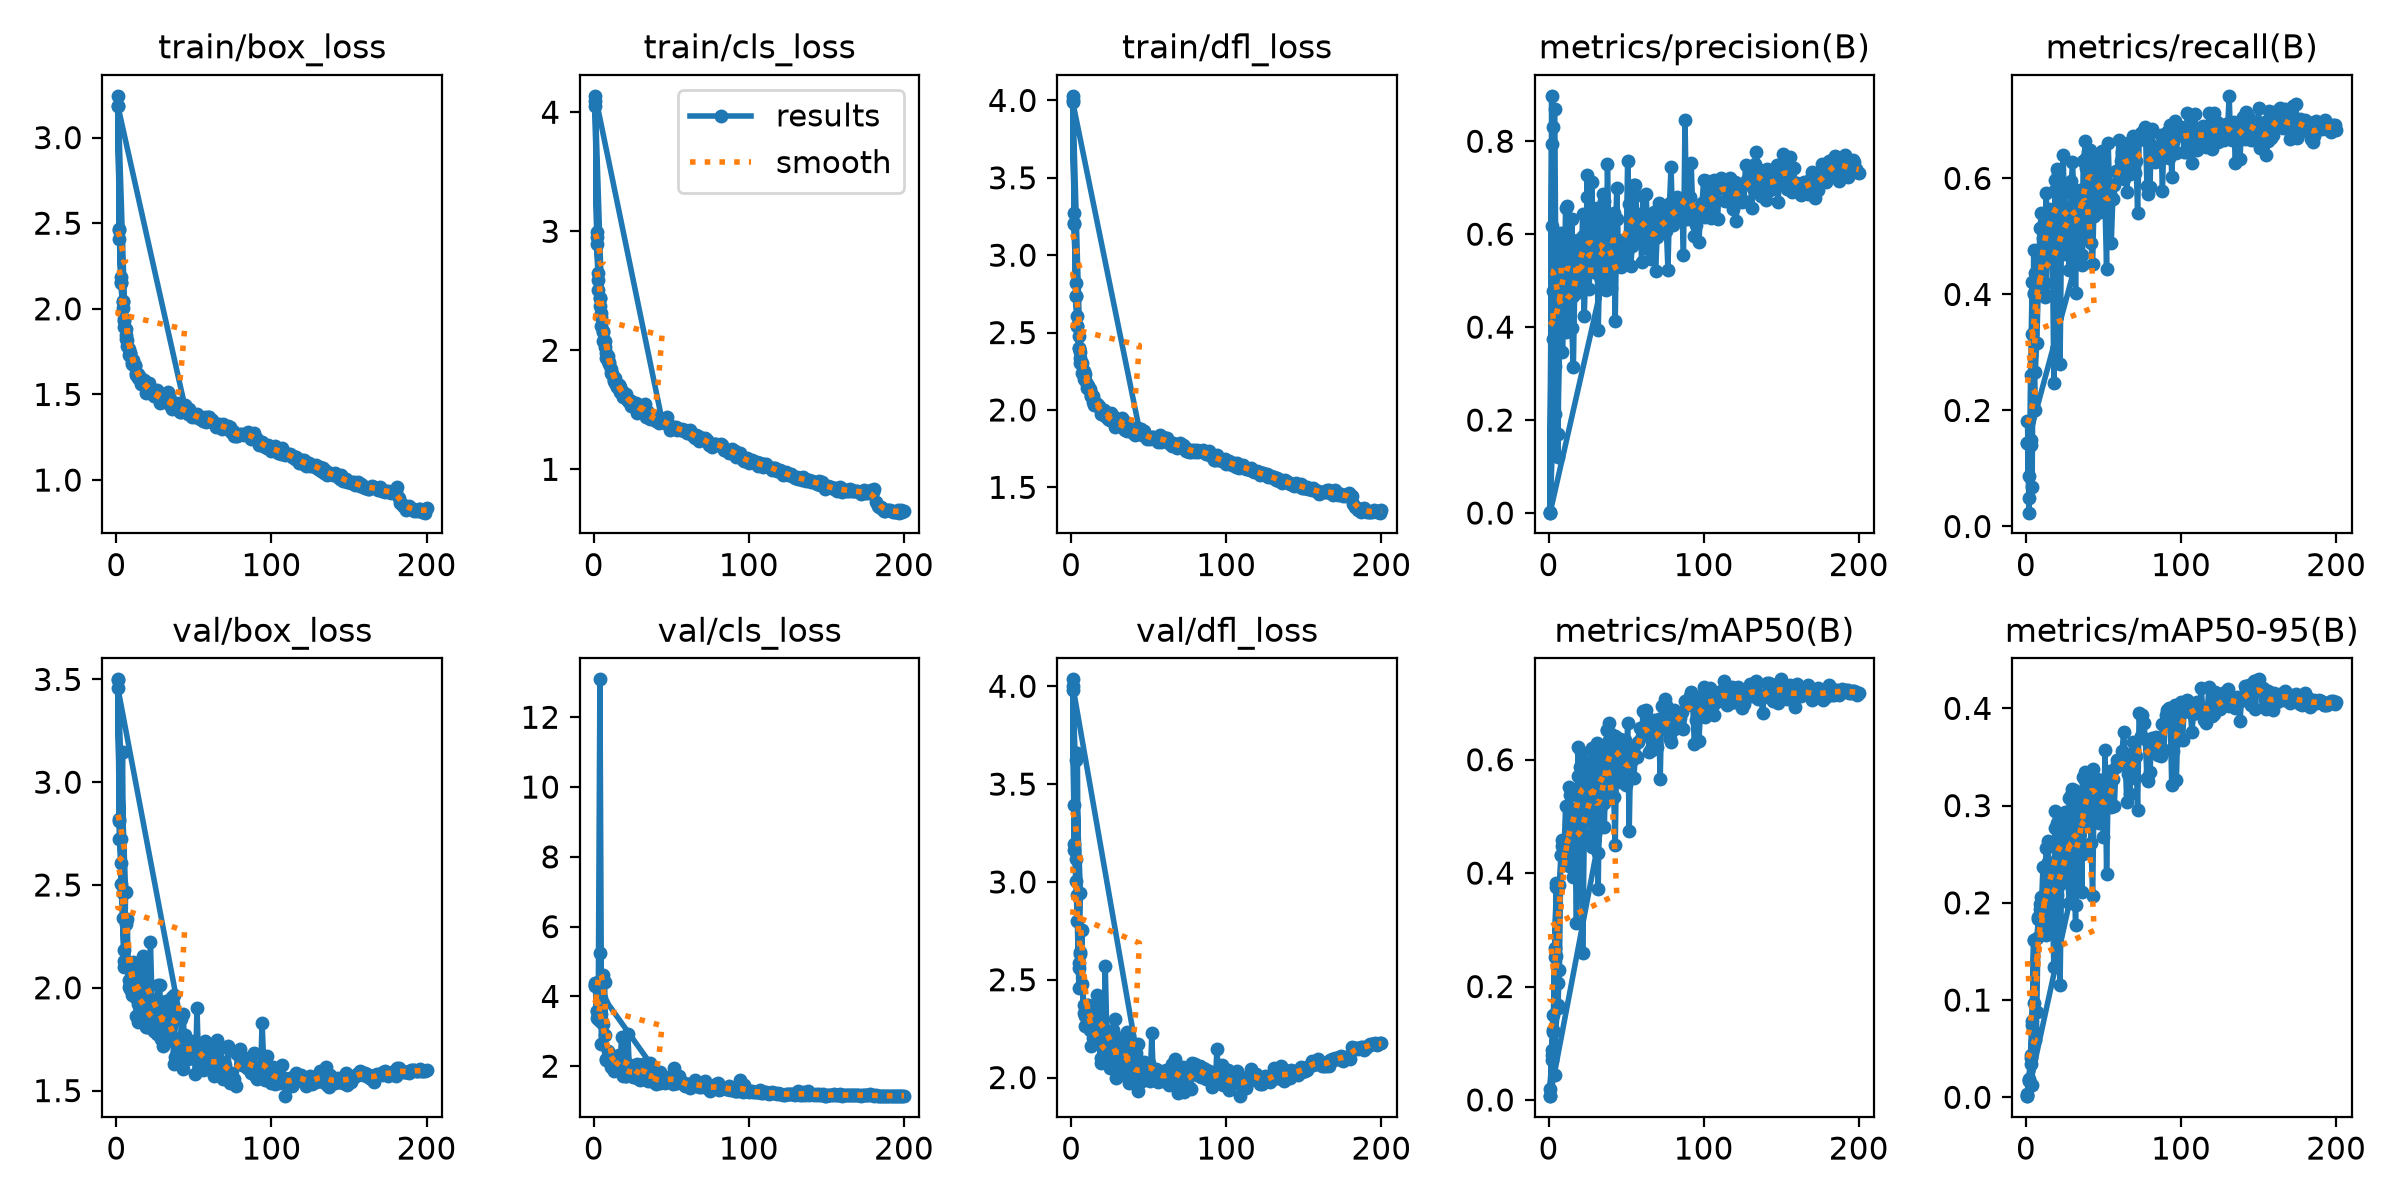

runs\neu_sdf_s_test\confusion_matrix_normalized.png


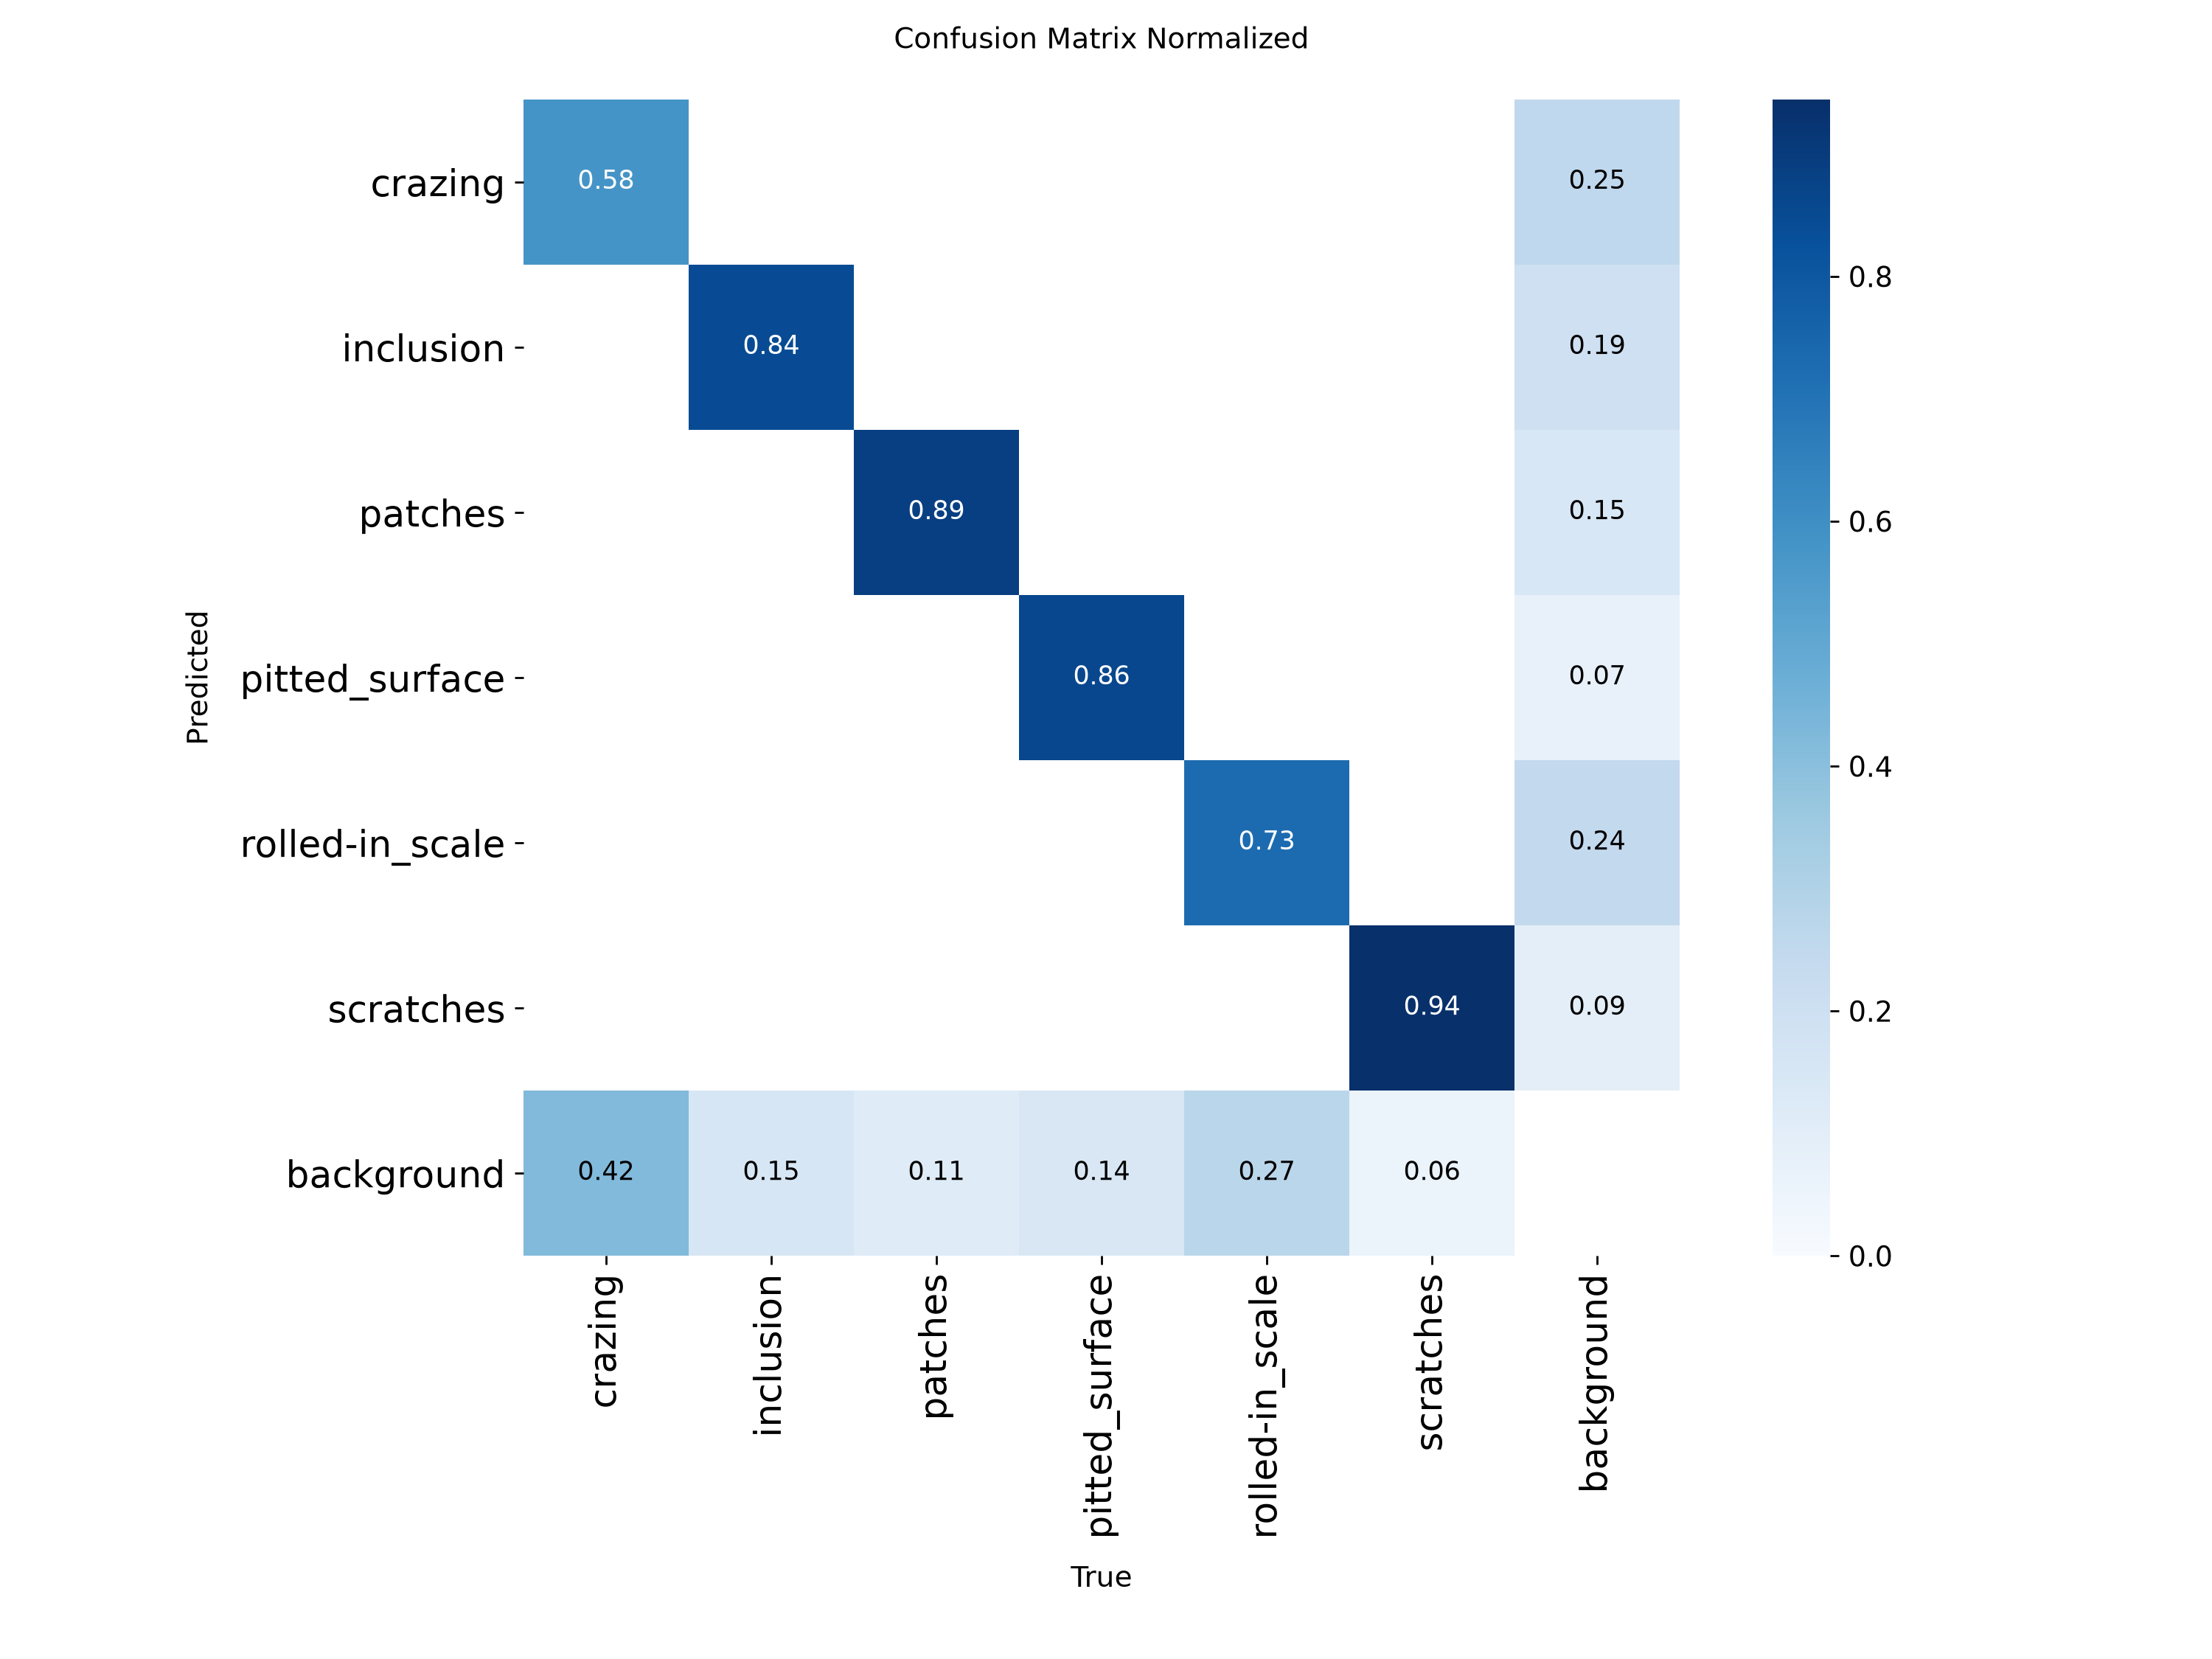

runs\neu_yolo11n\results.png


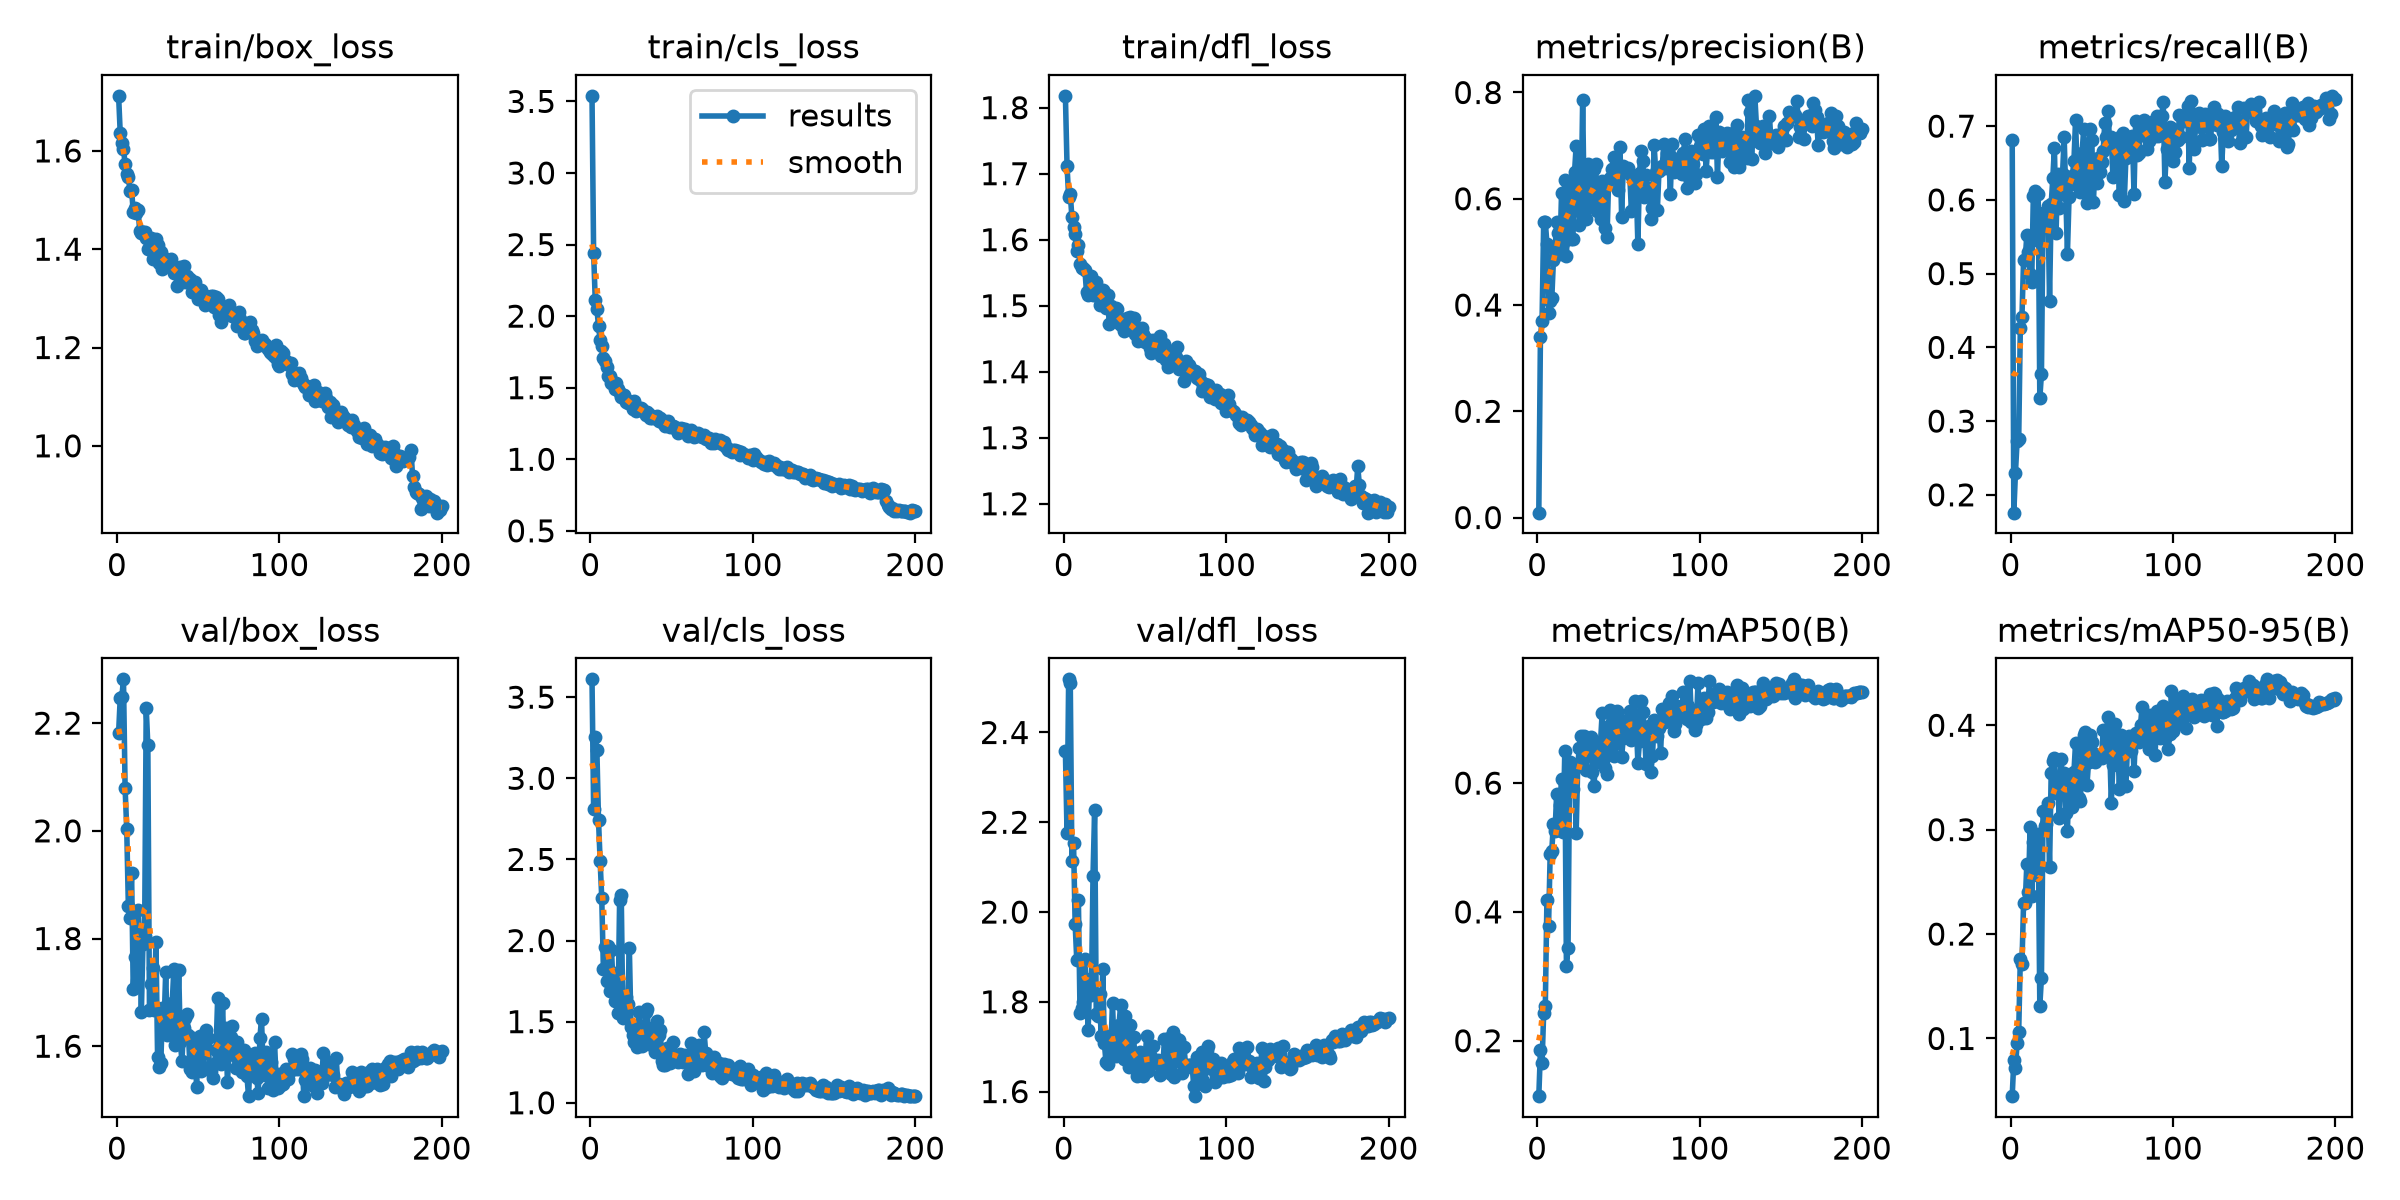

runs\neu_yolo11n_test\confusion_matrix_normalized.png


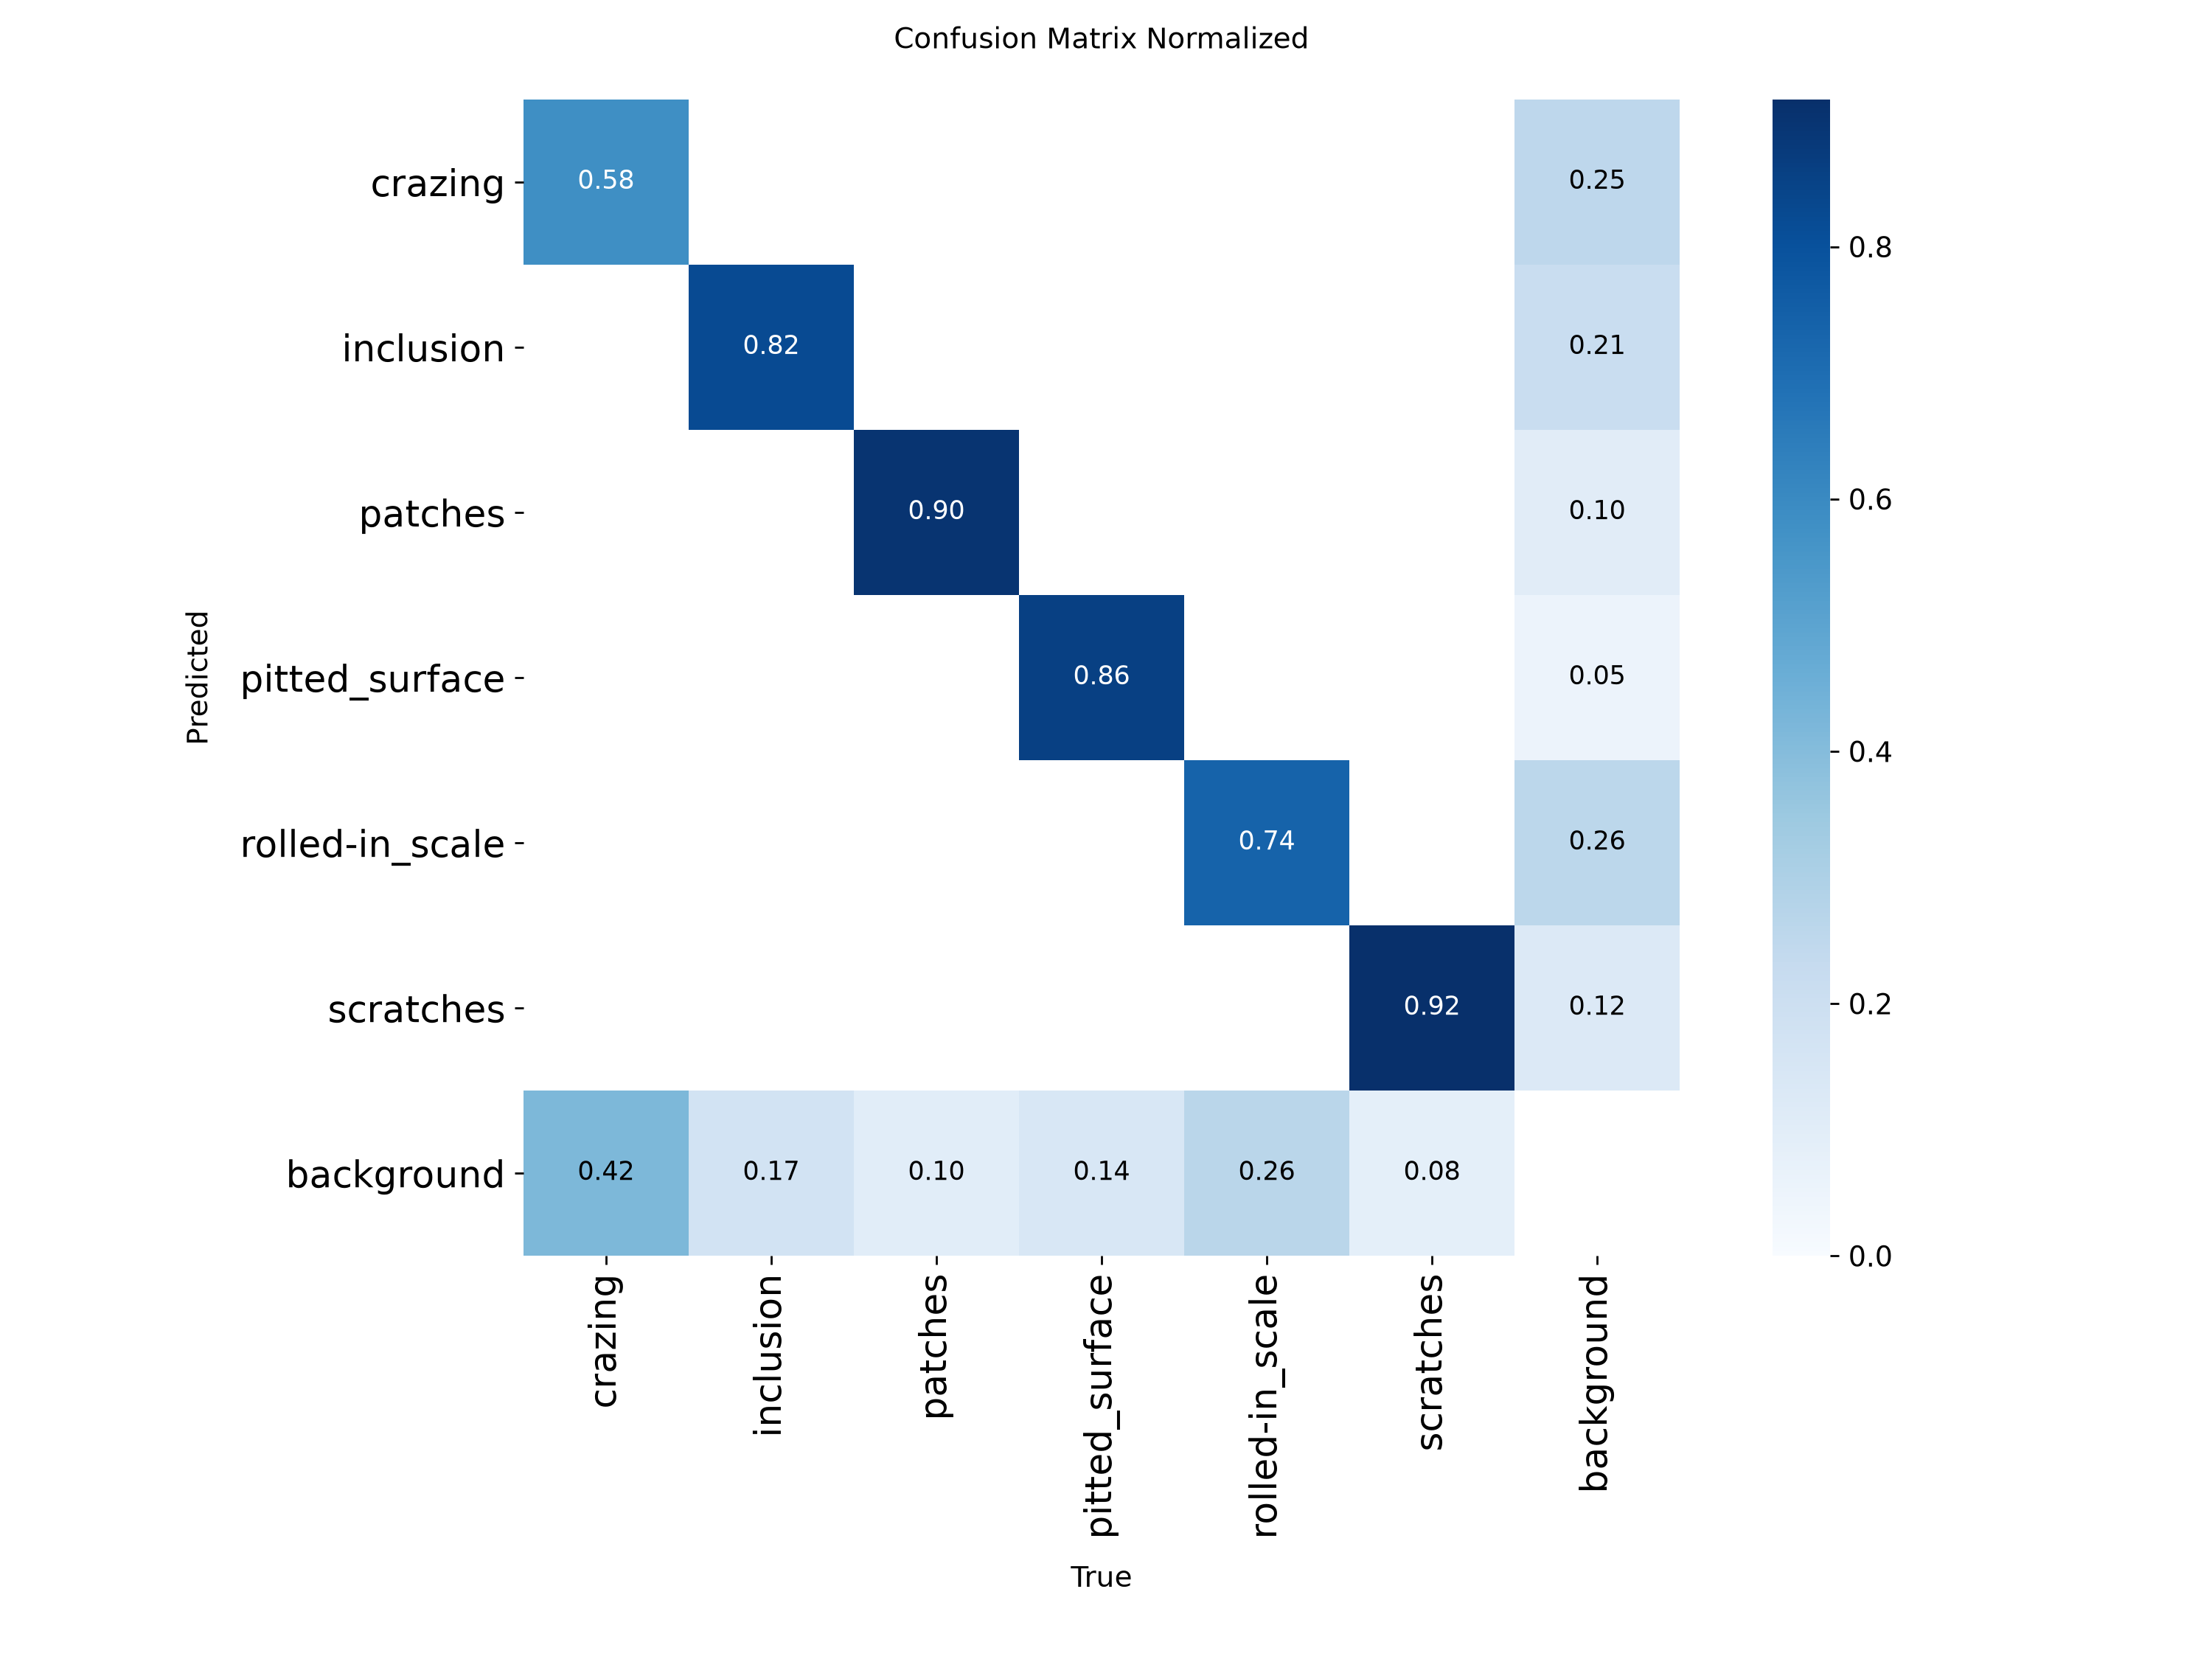

runs\neu_yolo11s\results.png


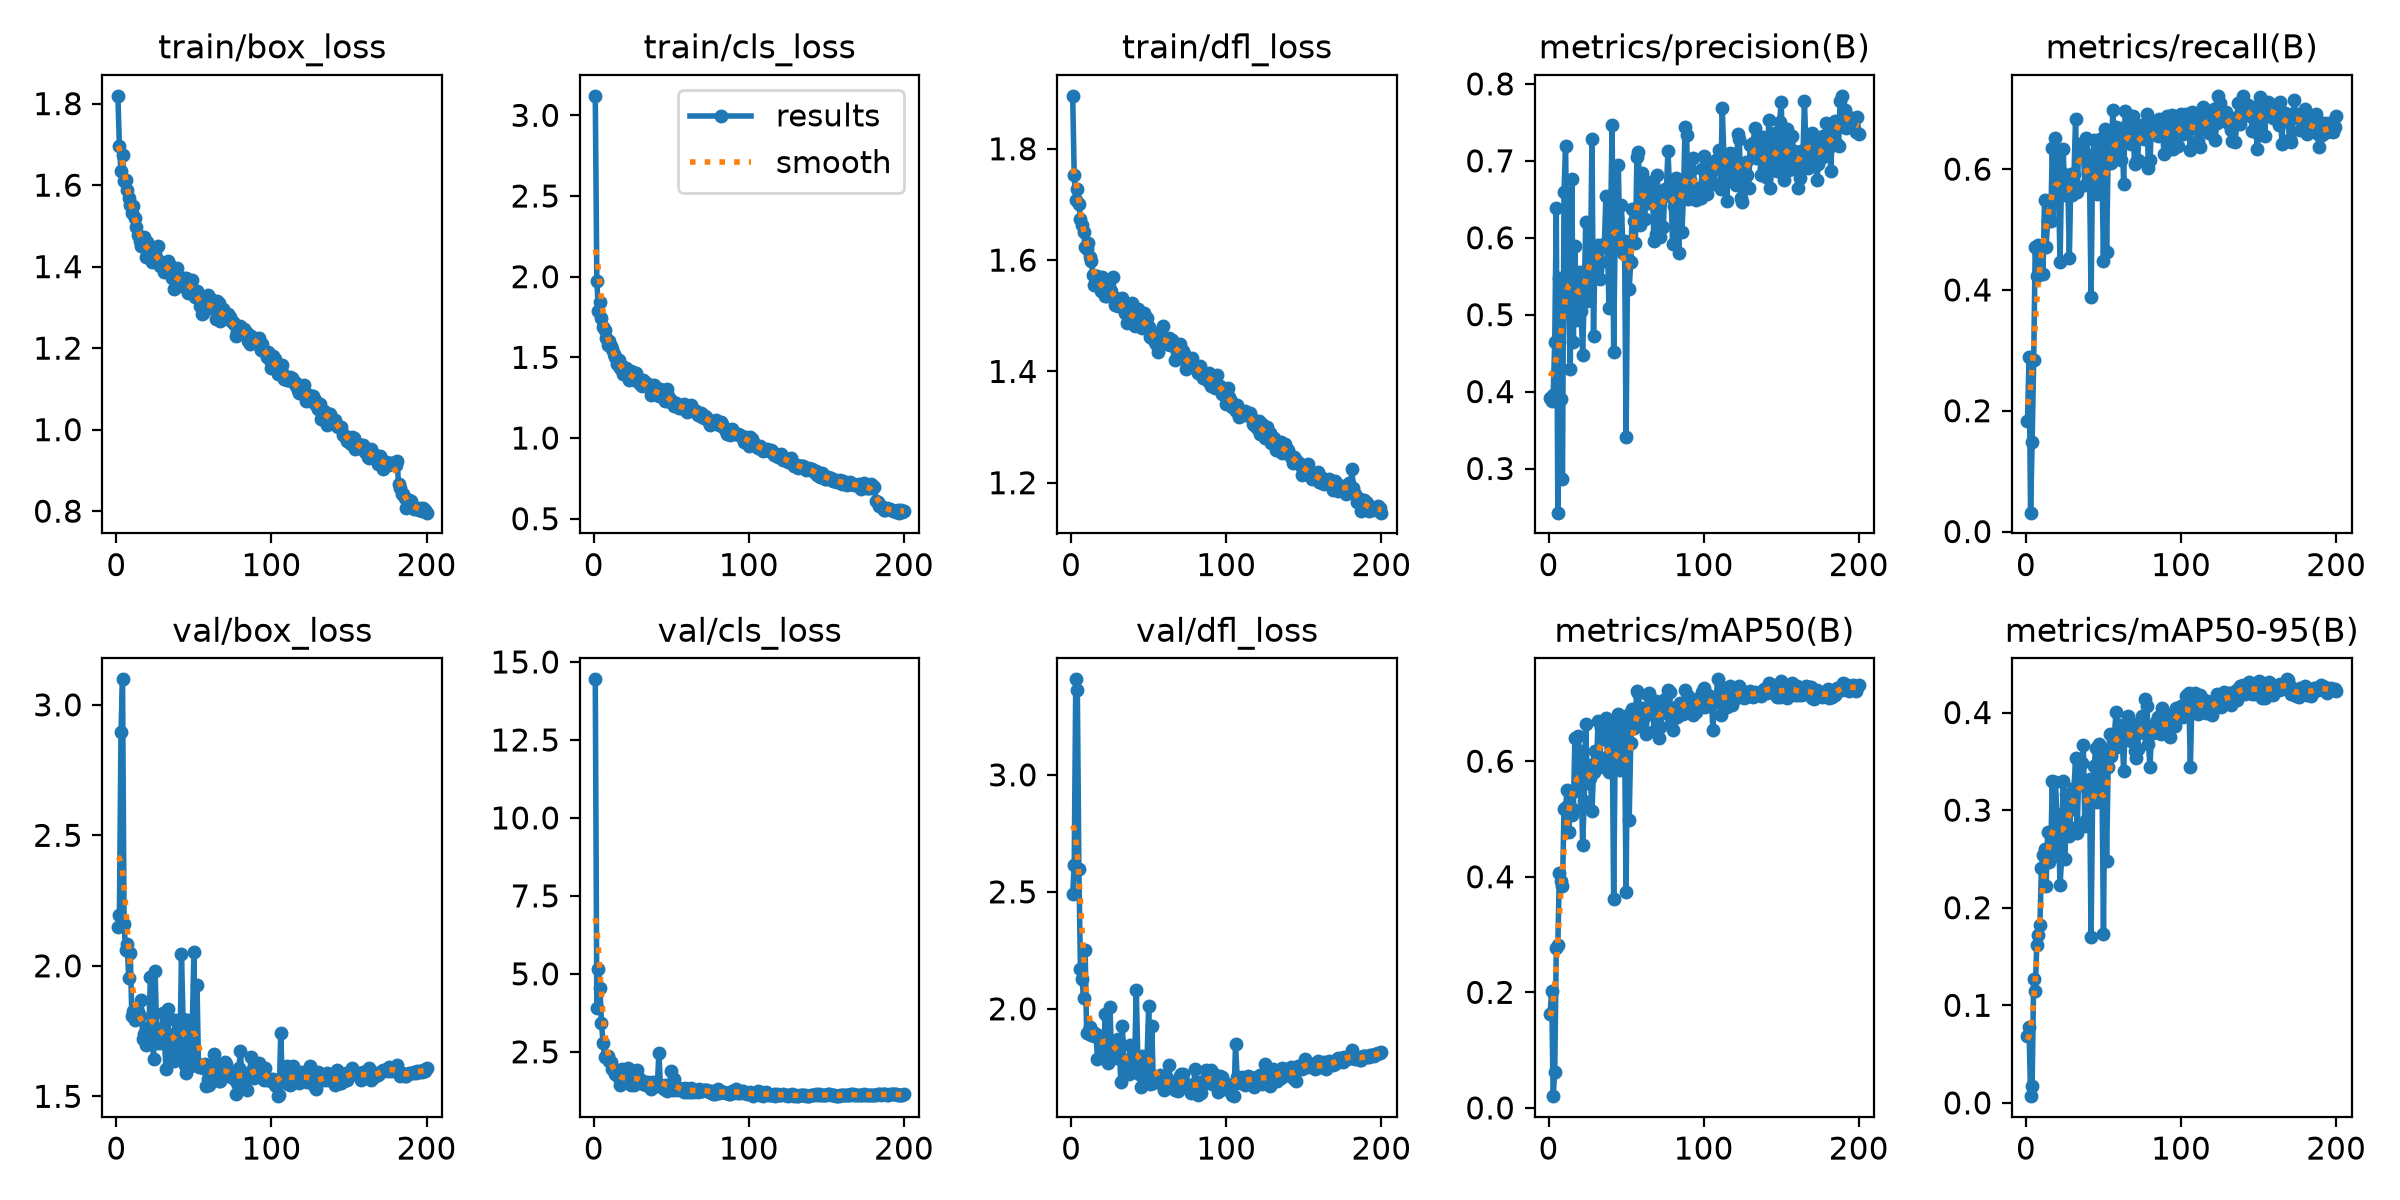

runs\neu_yolo11s_test\confusion_matrix_normalized.png


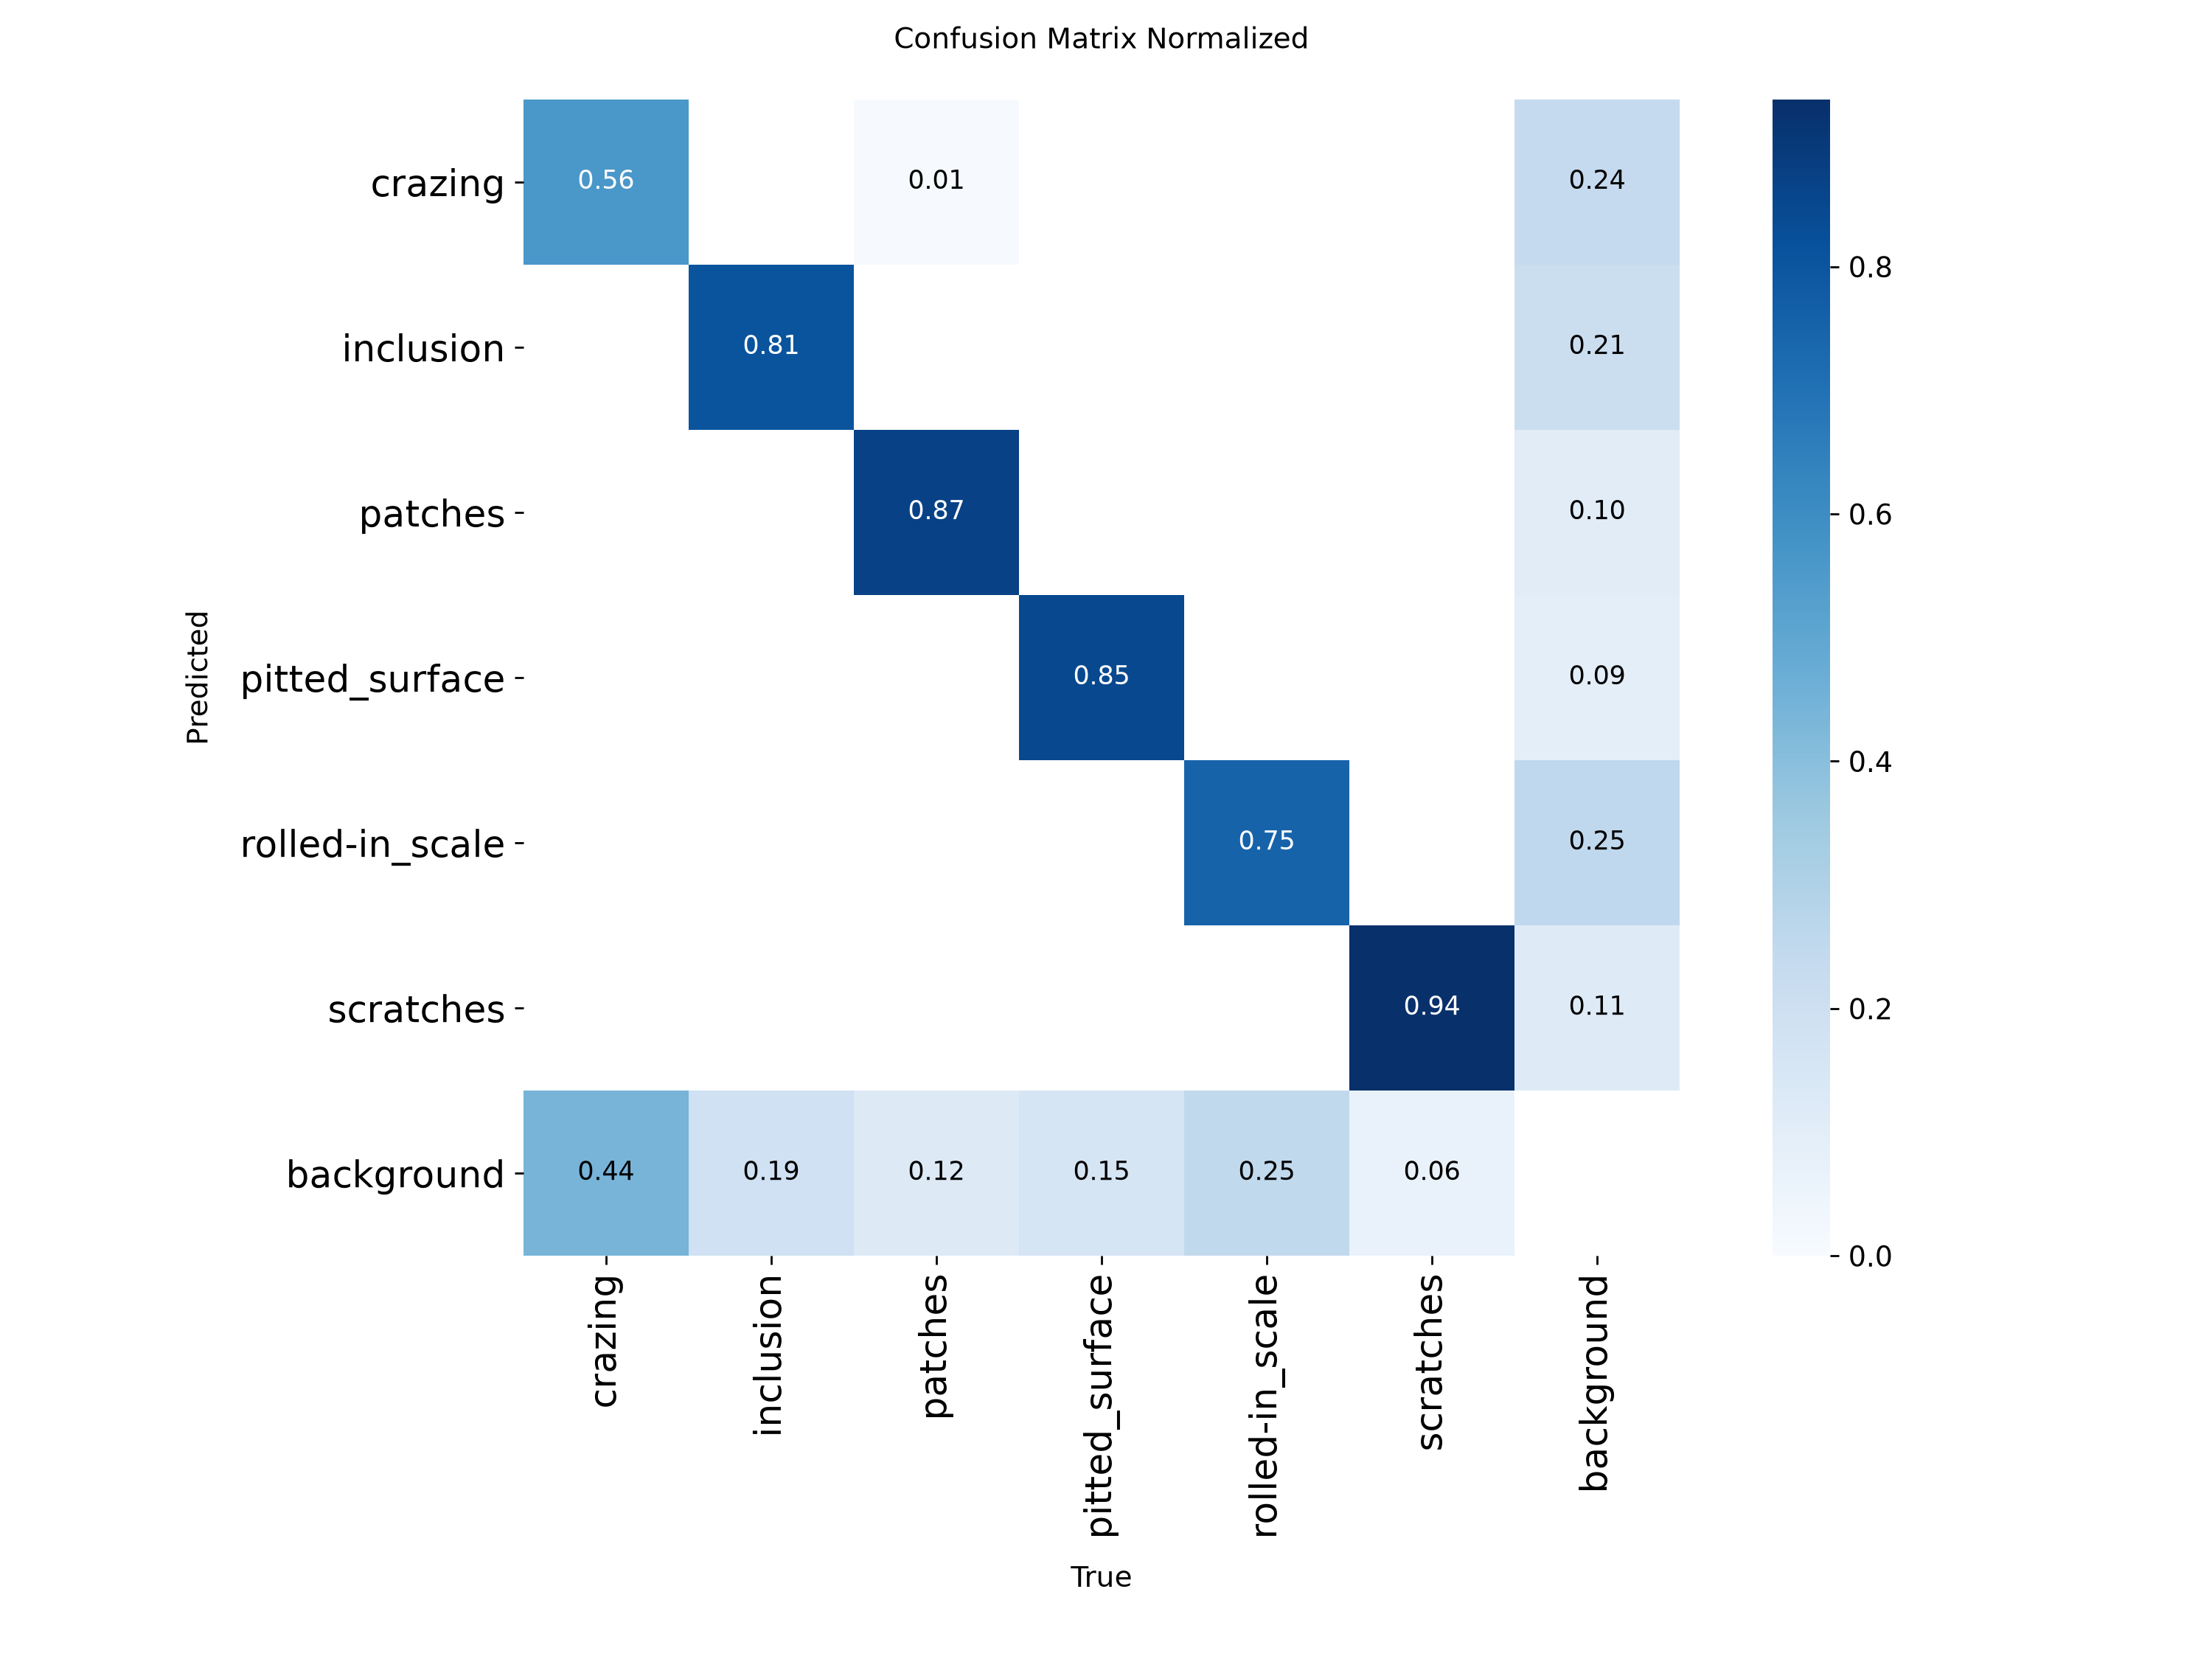

runs\neu_yolo12s\results.png


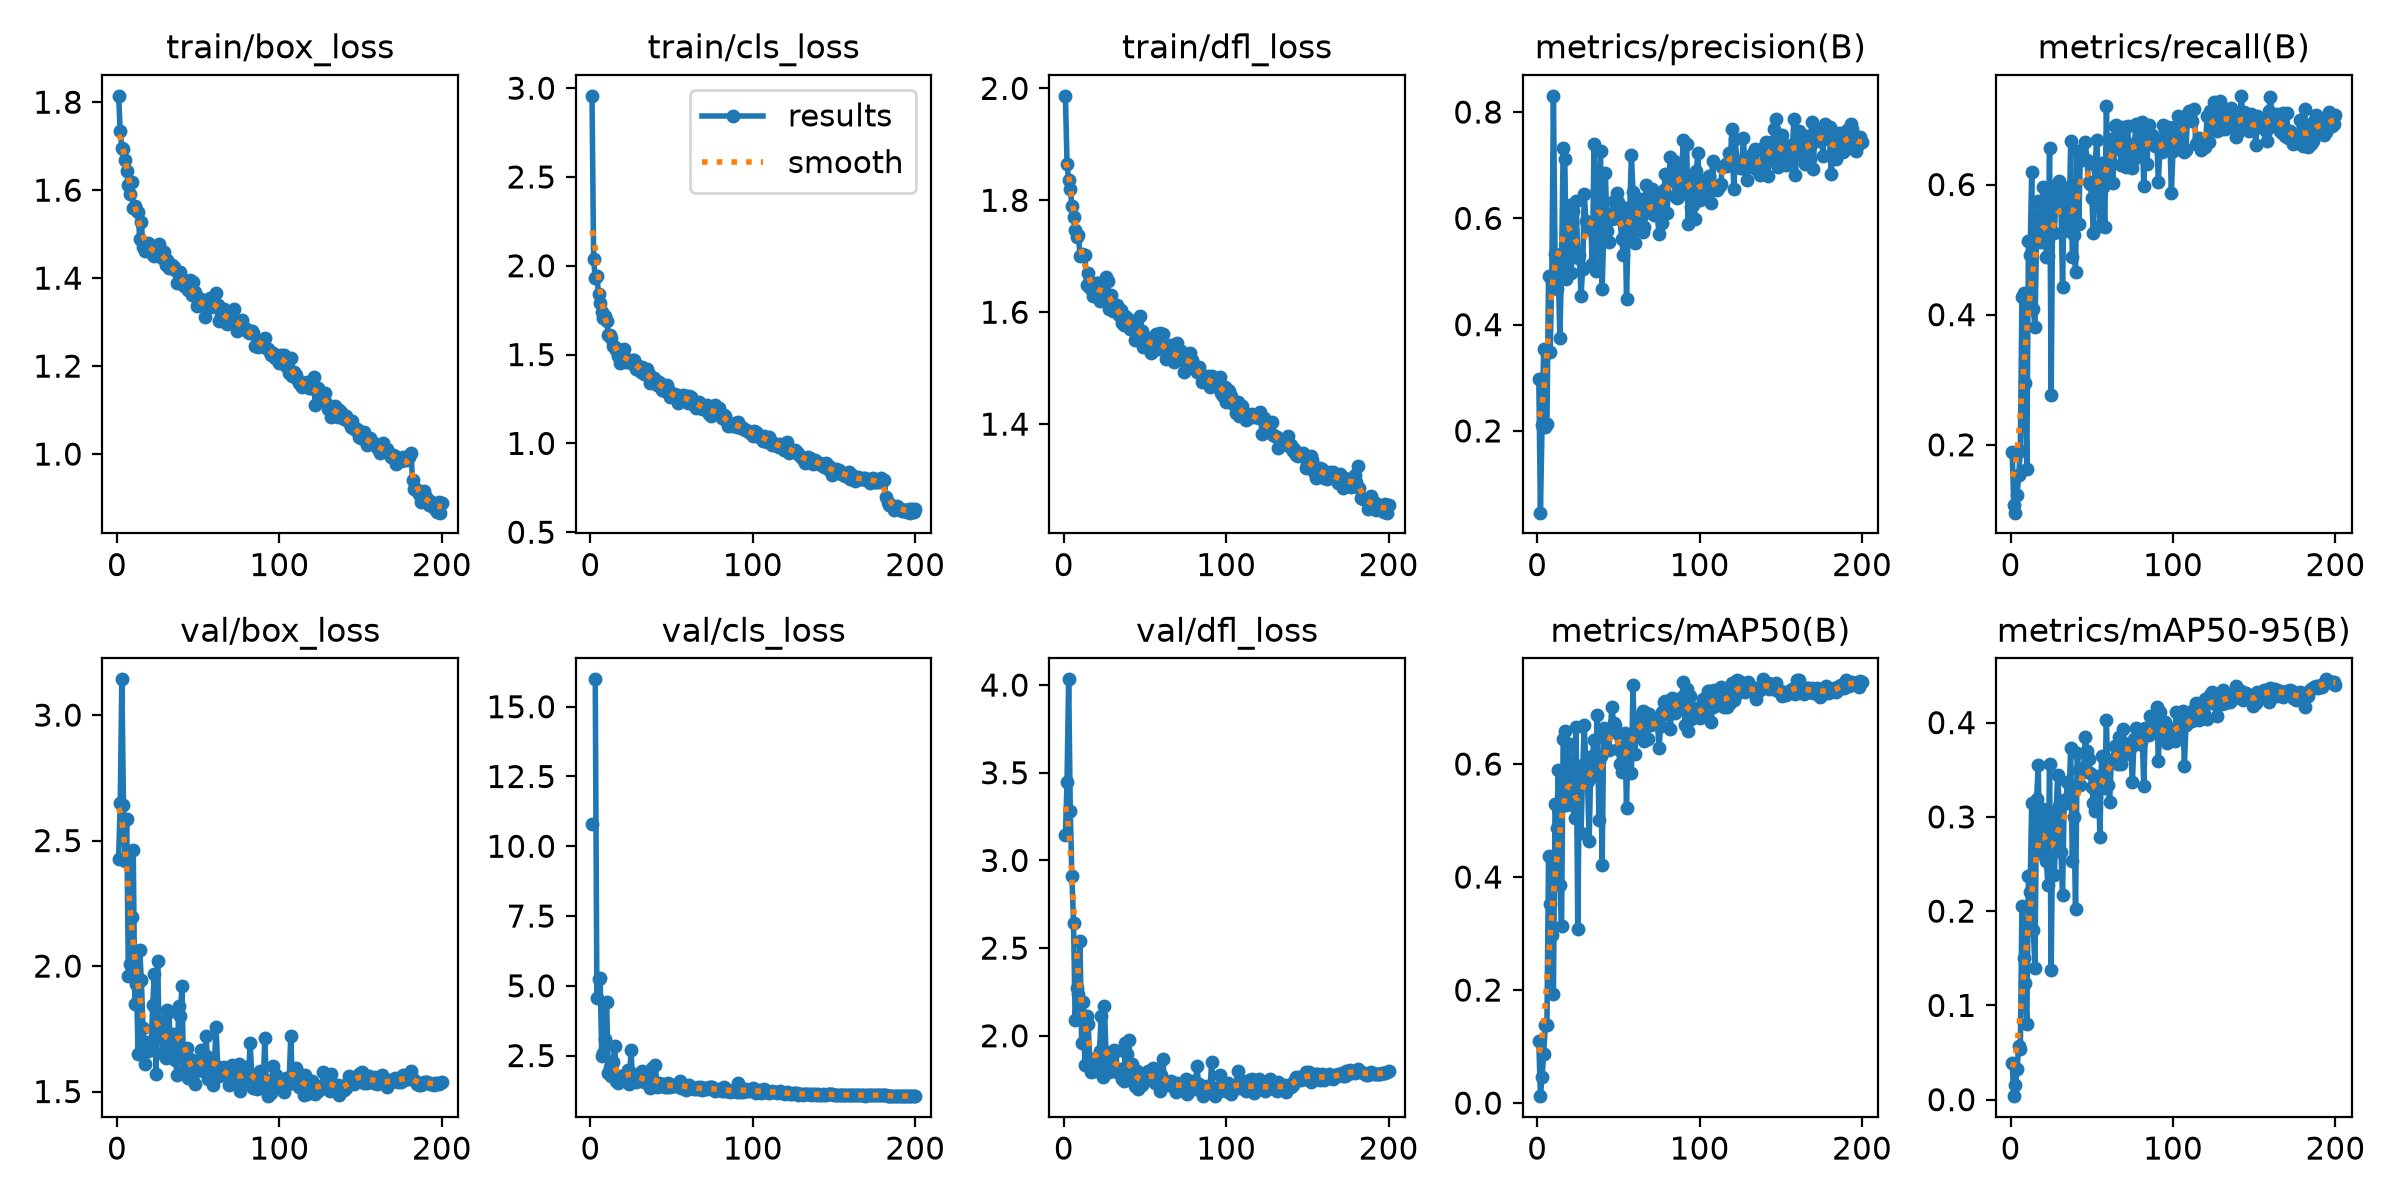

runs\neu_yolo12s_test\confusion_matrix_normalized.png


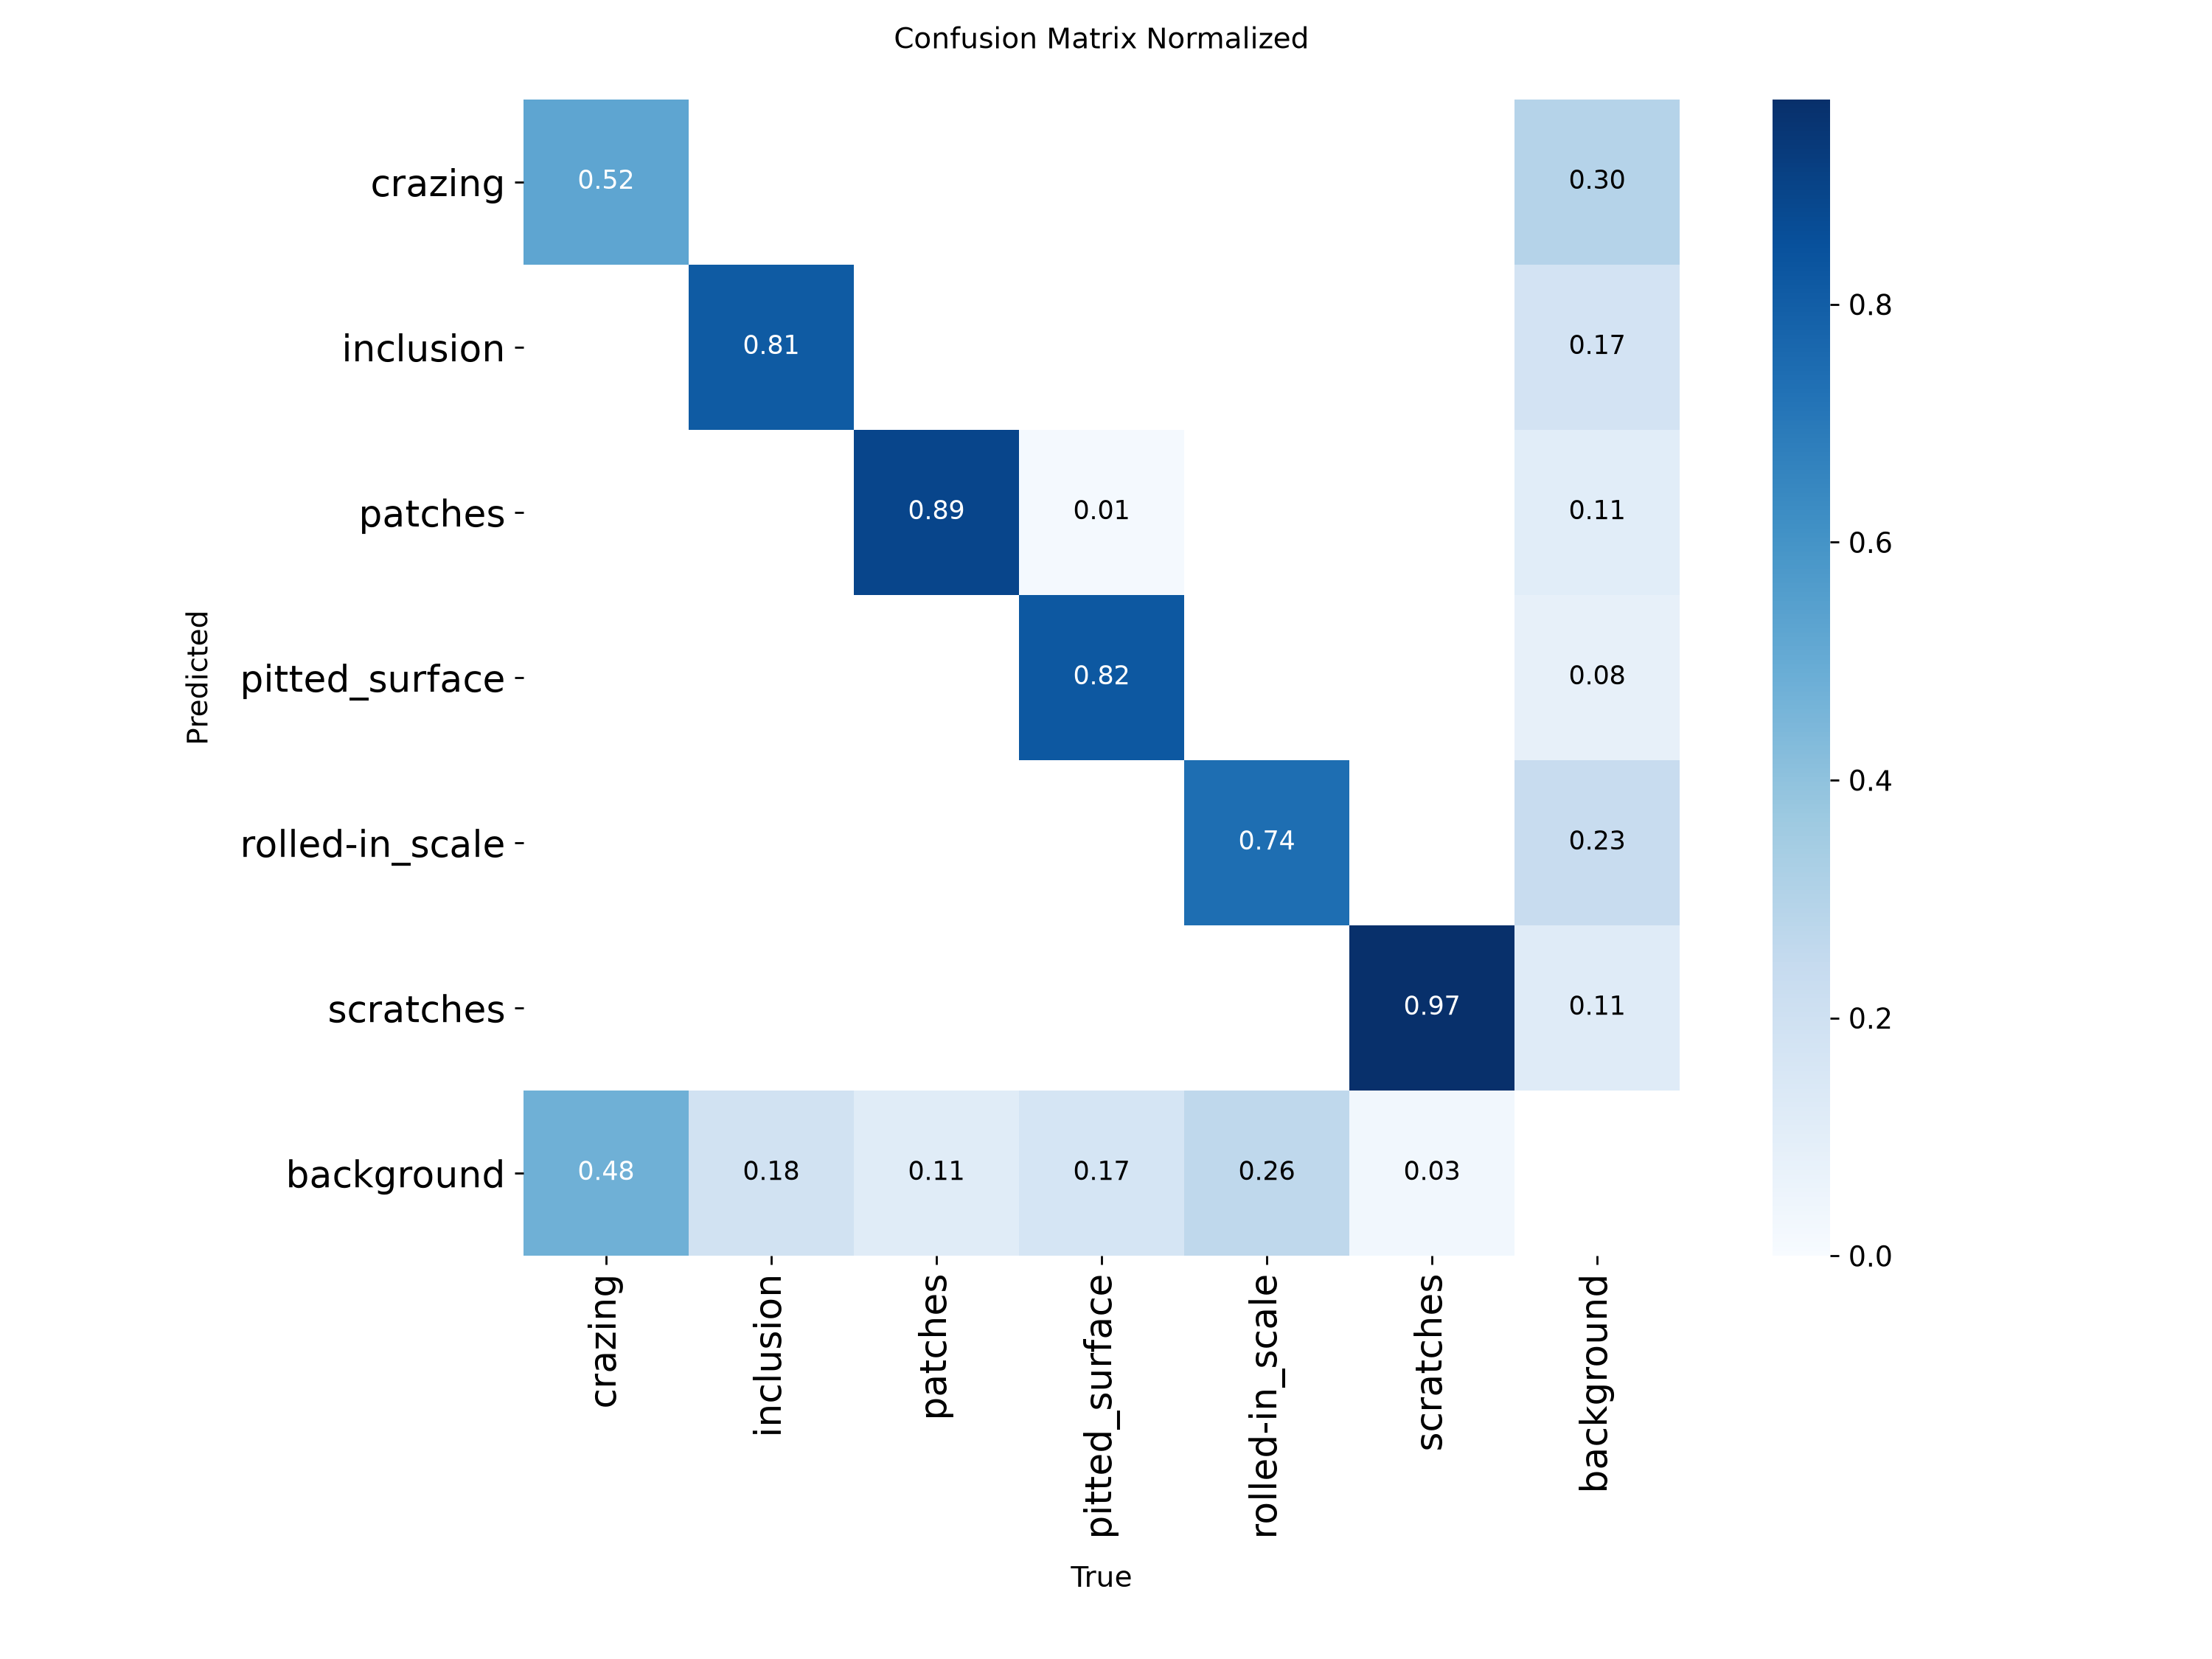

runs\neu_yolov10s\results.png


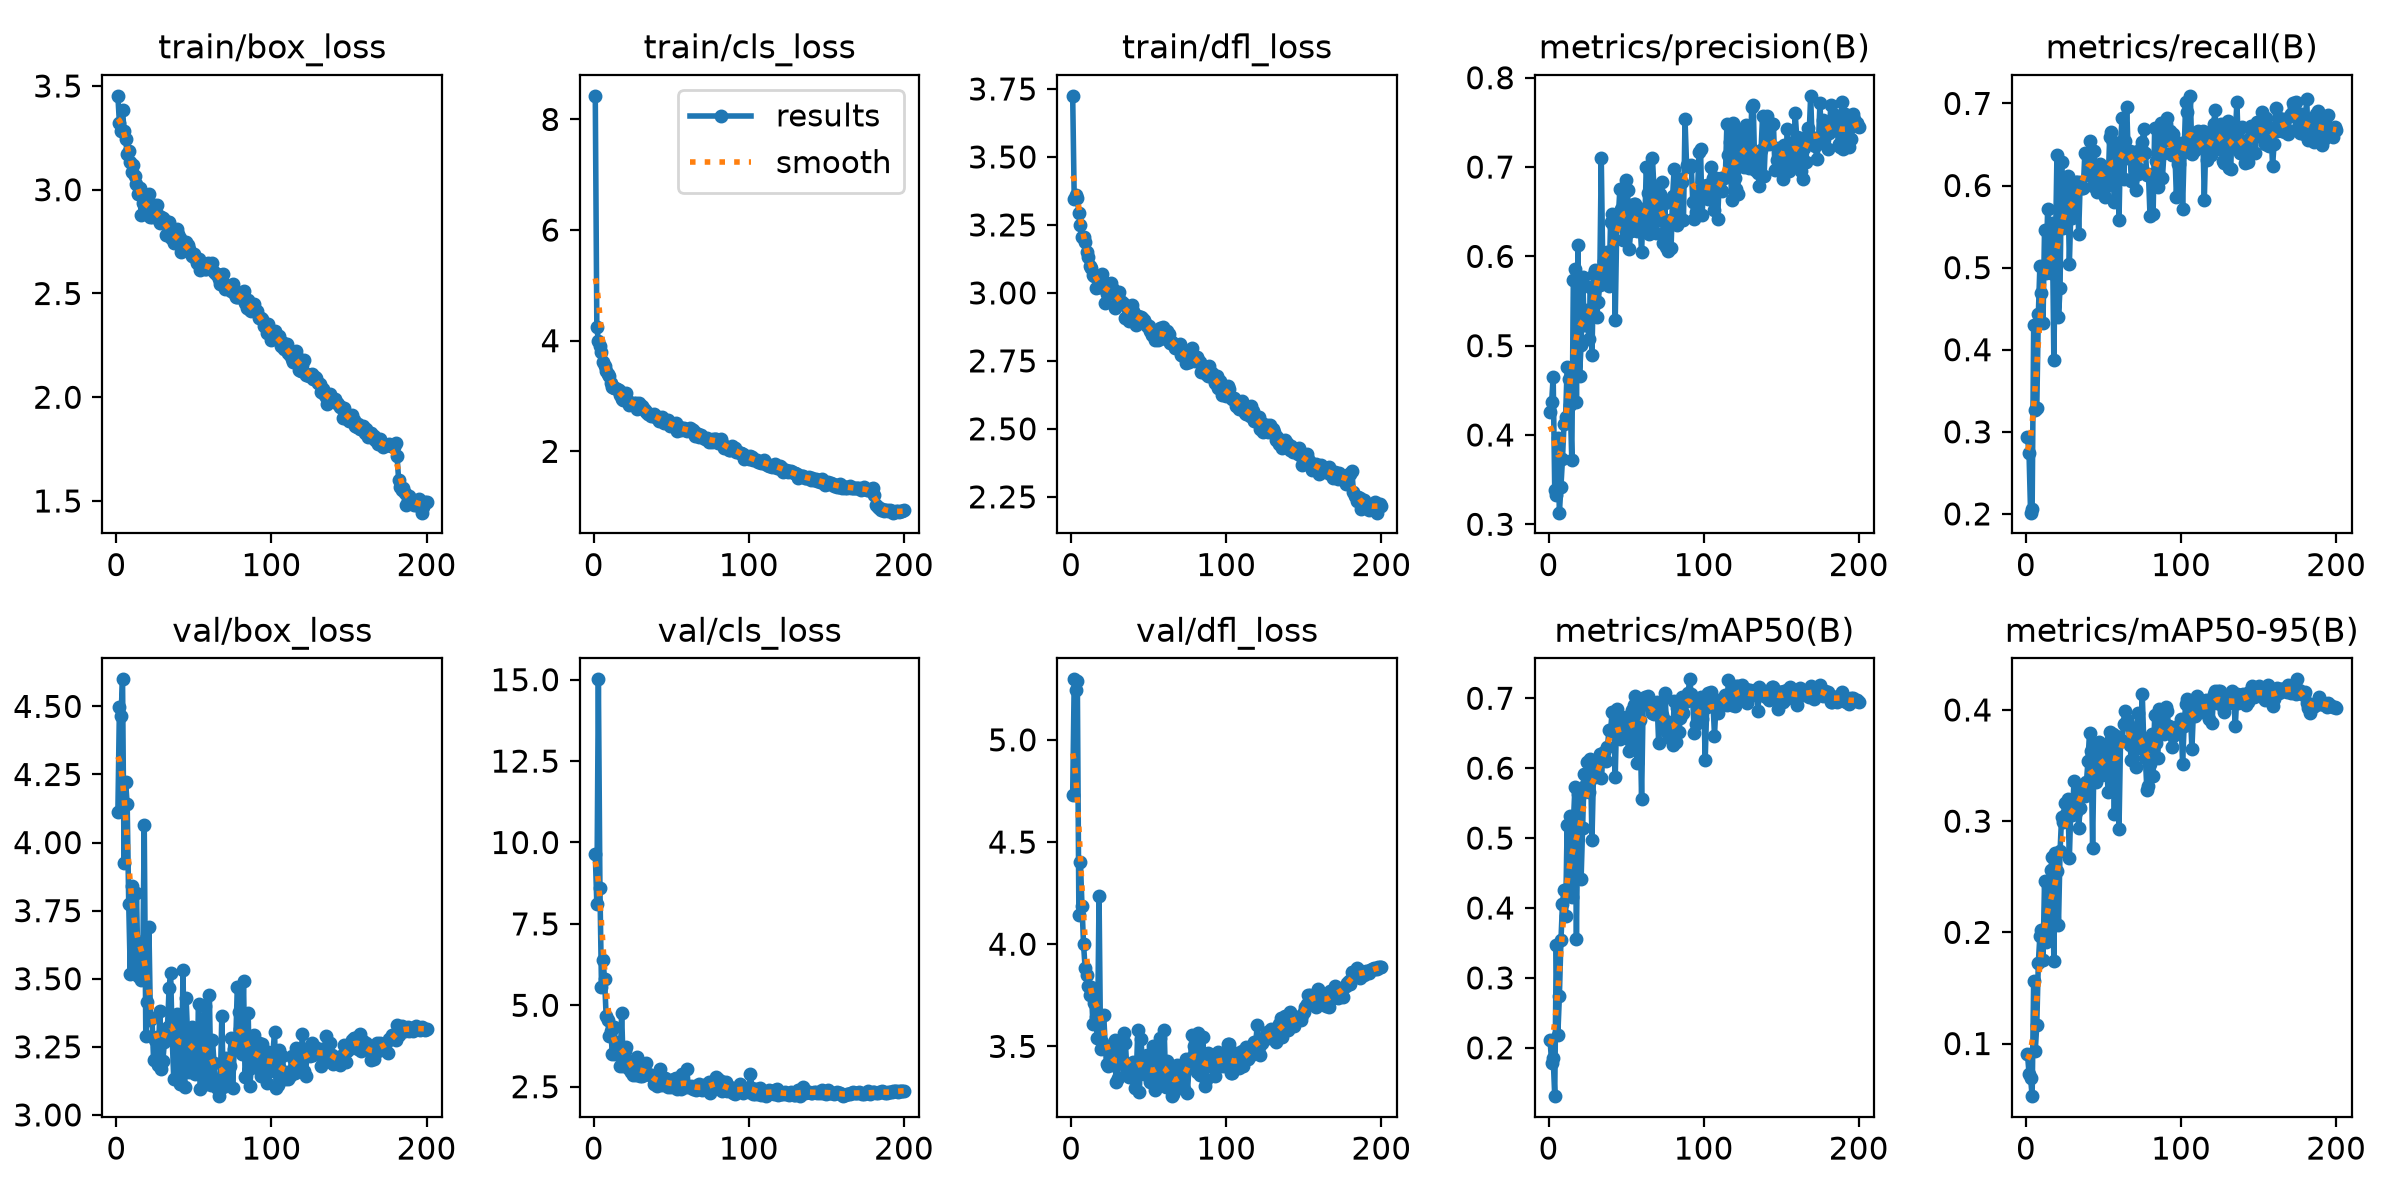

runs\neu_yolov10s_test\confusion_matrix_normalized.png


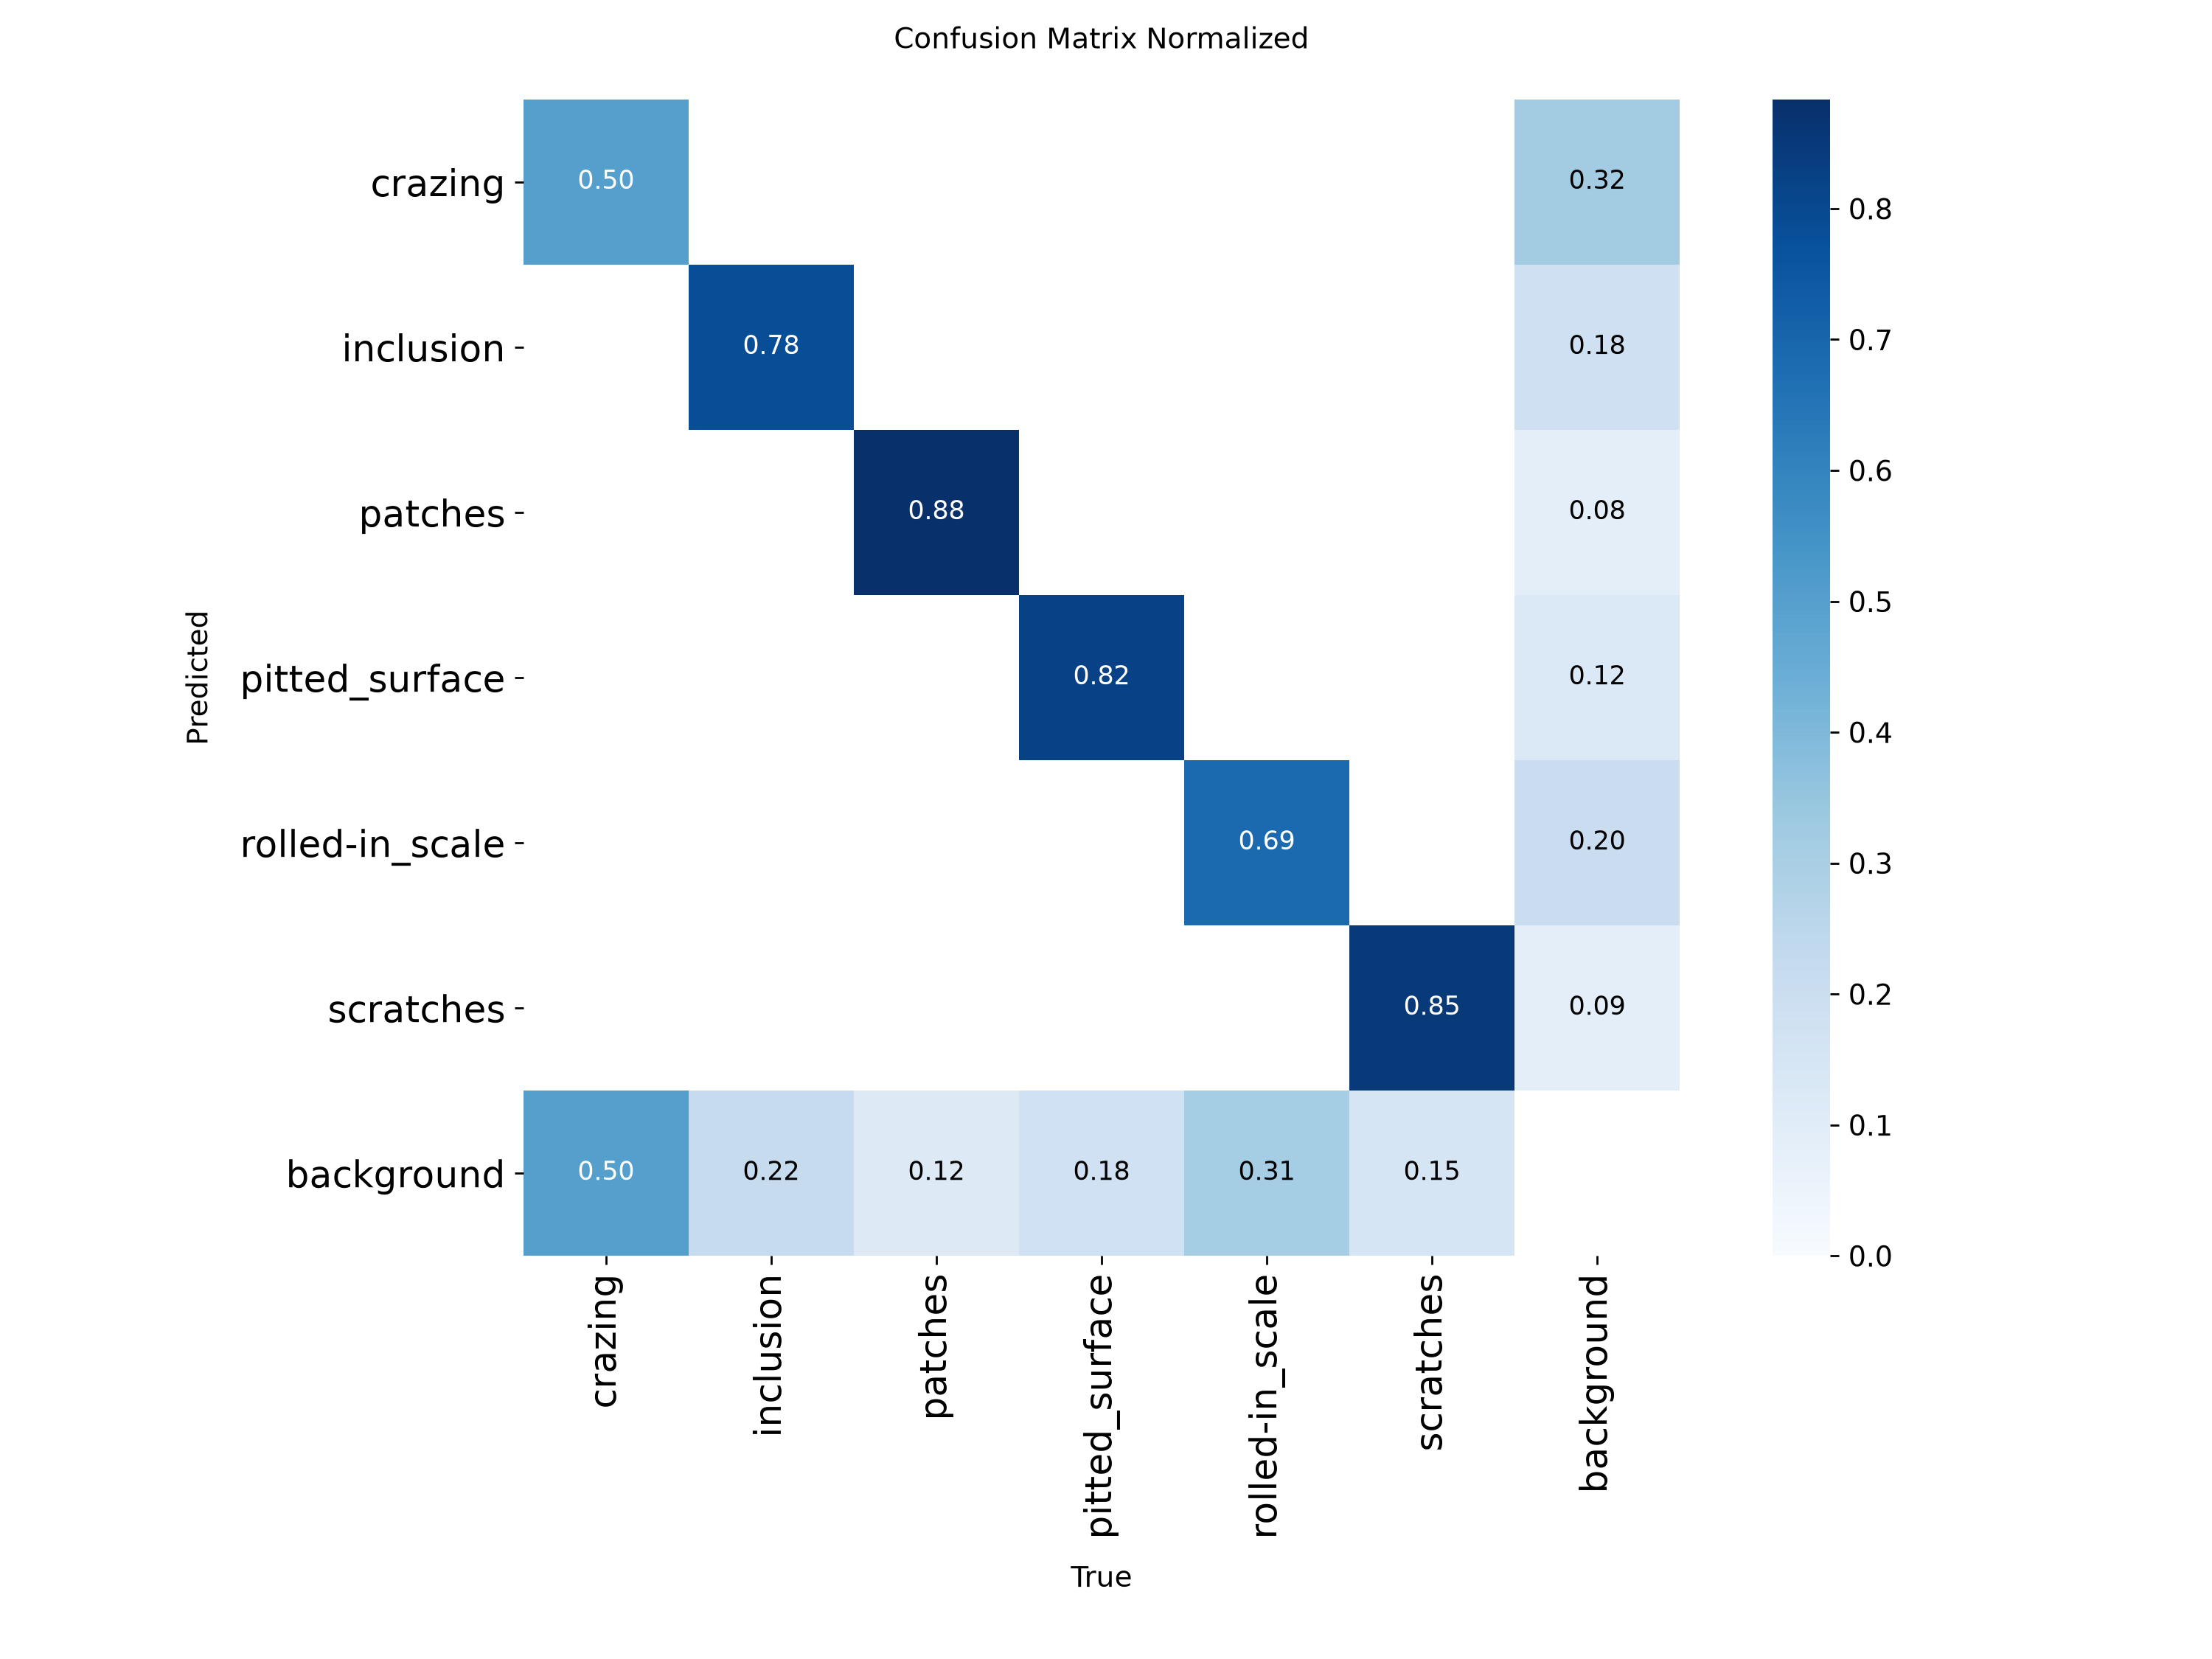

runs\neu_yolov5su\results.png


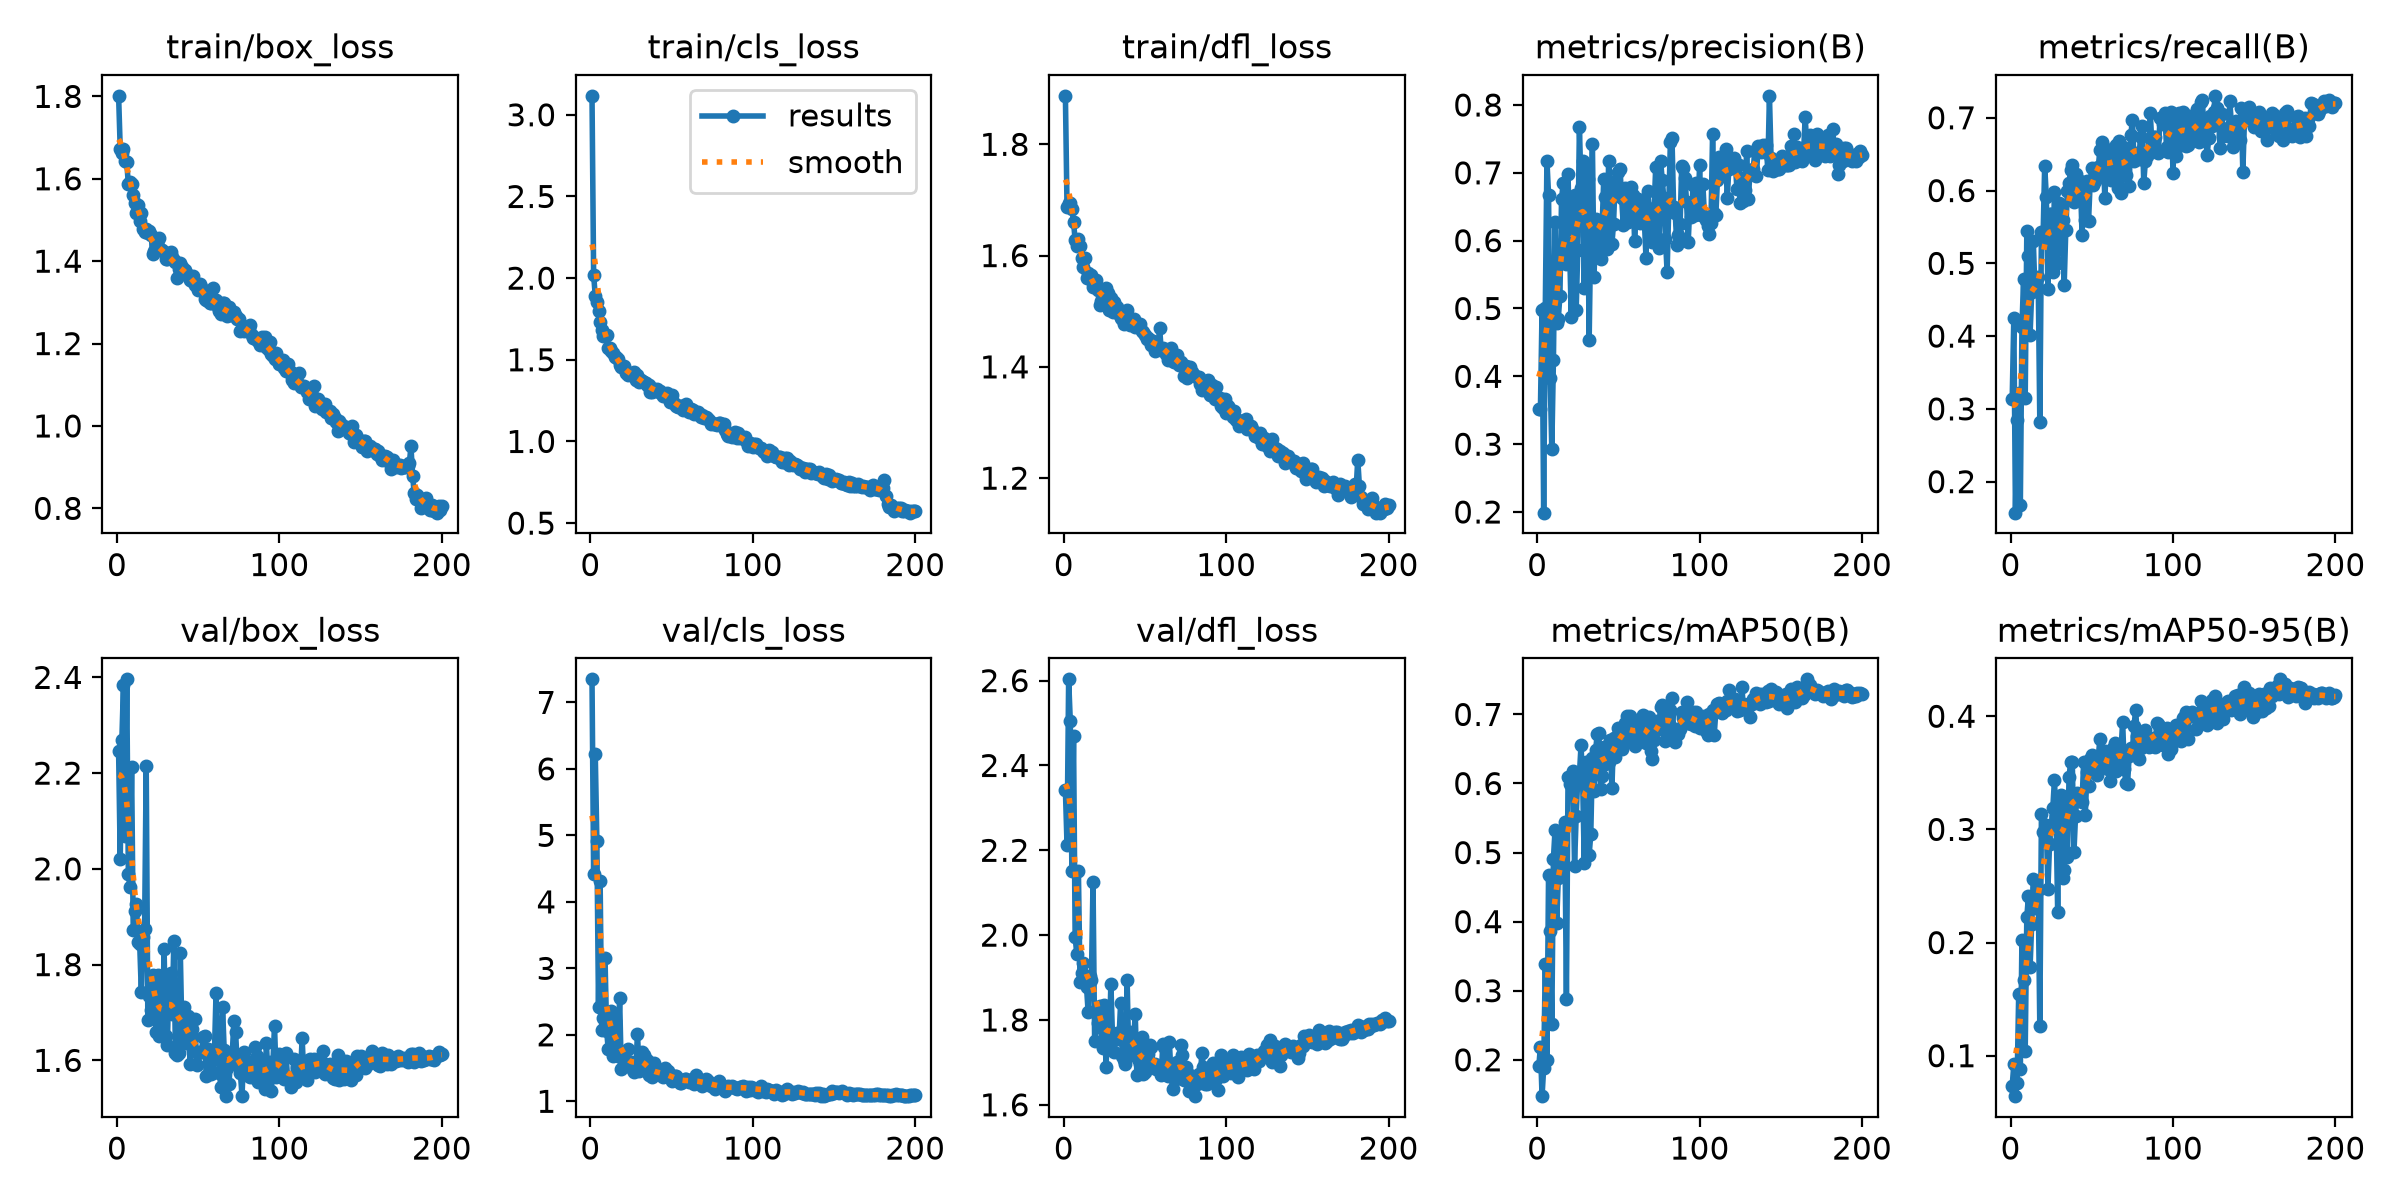

runs\neu_yolov5su_test\confusion_matrix_normalized.png


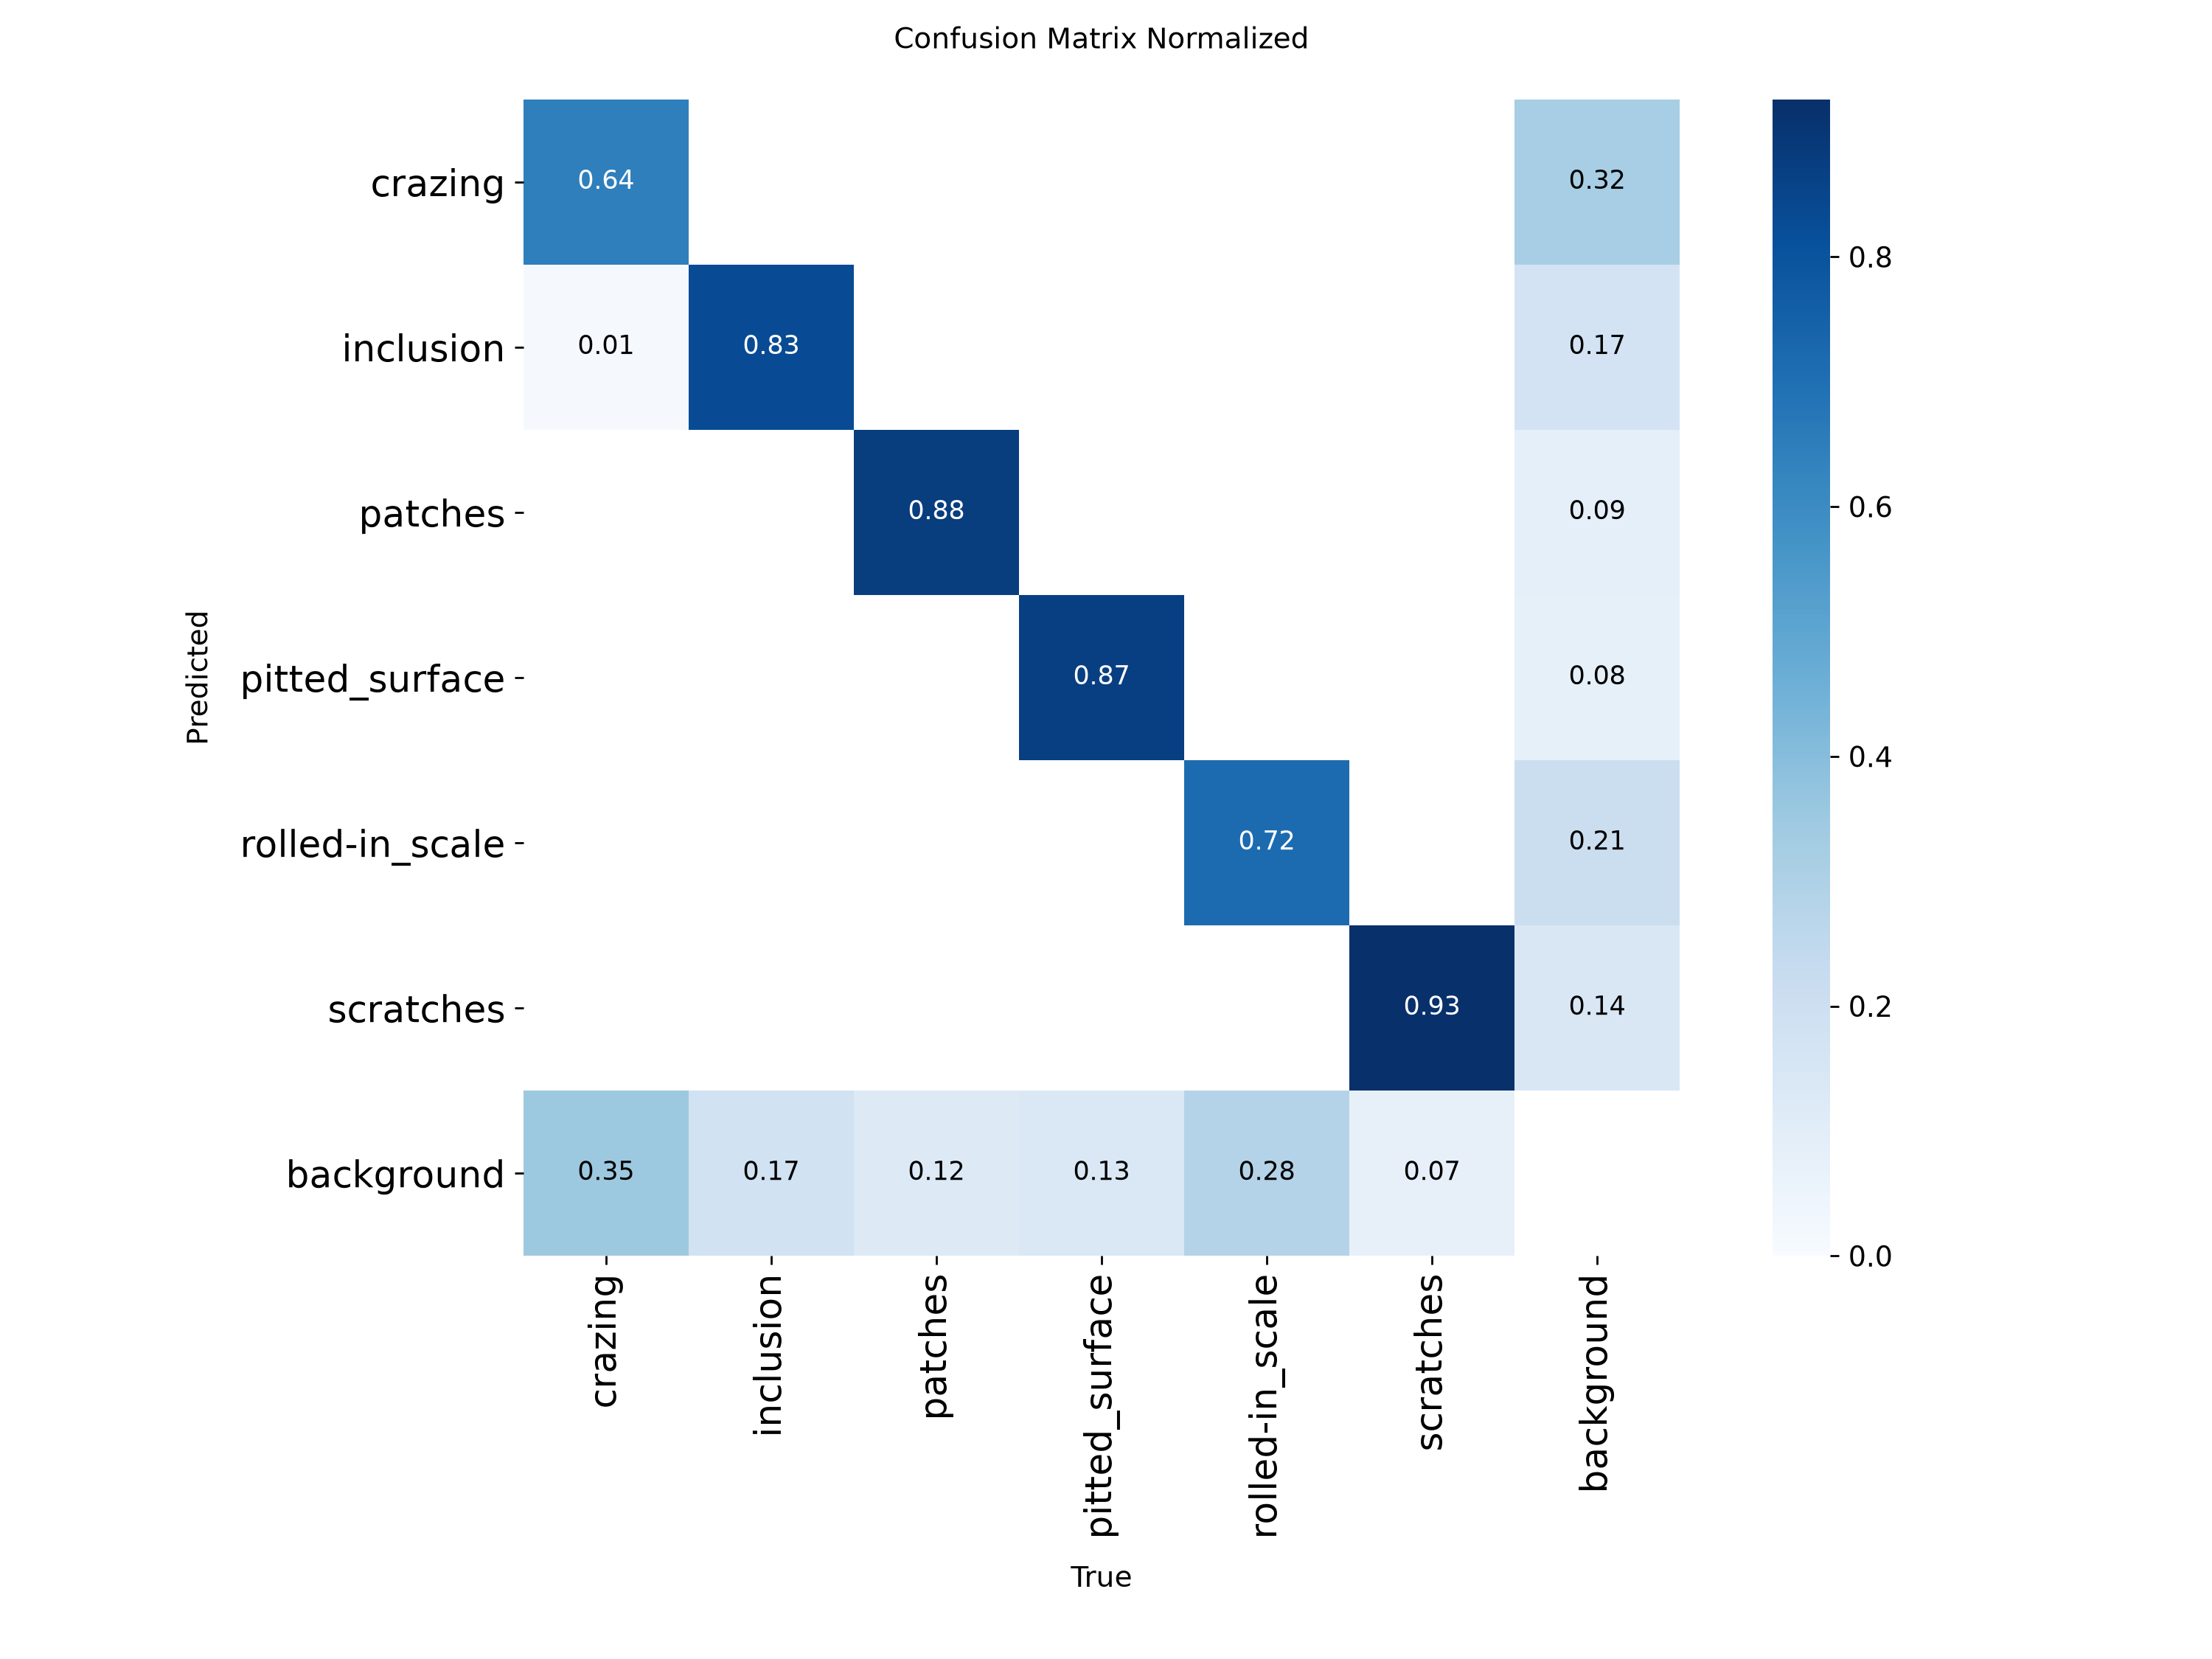

runs\neu_yolov8s\results.png


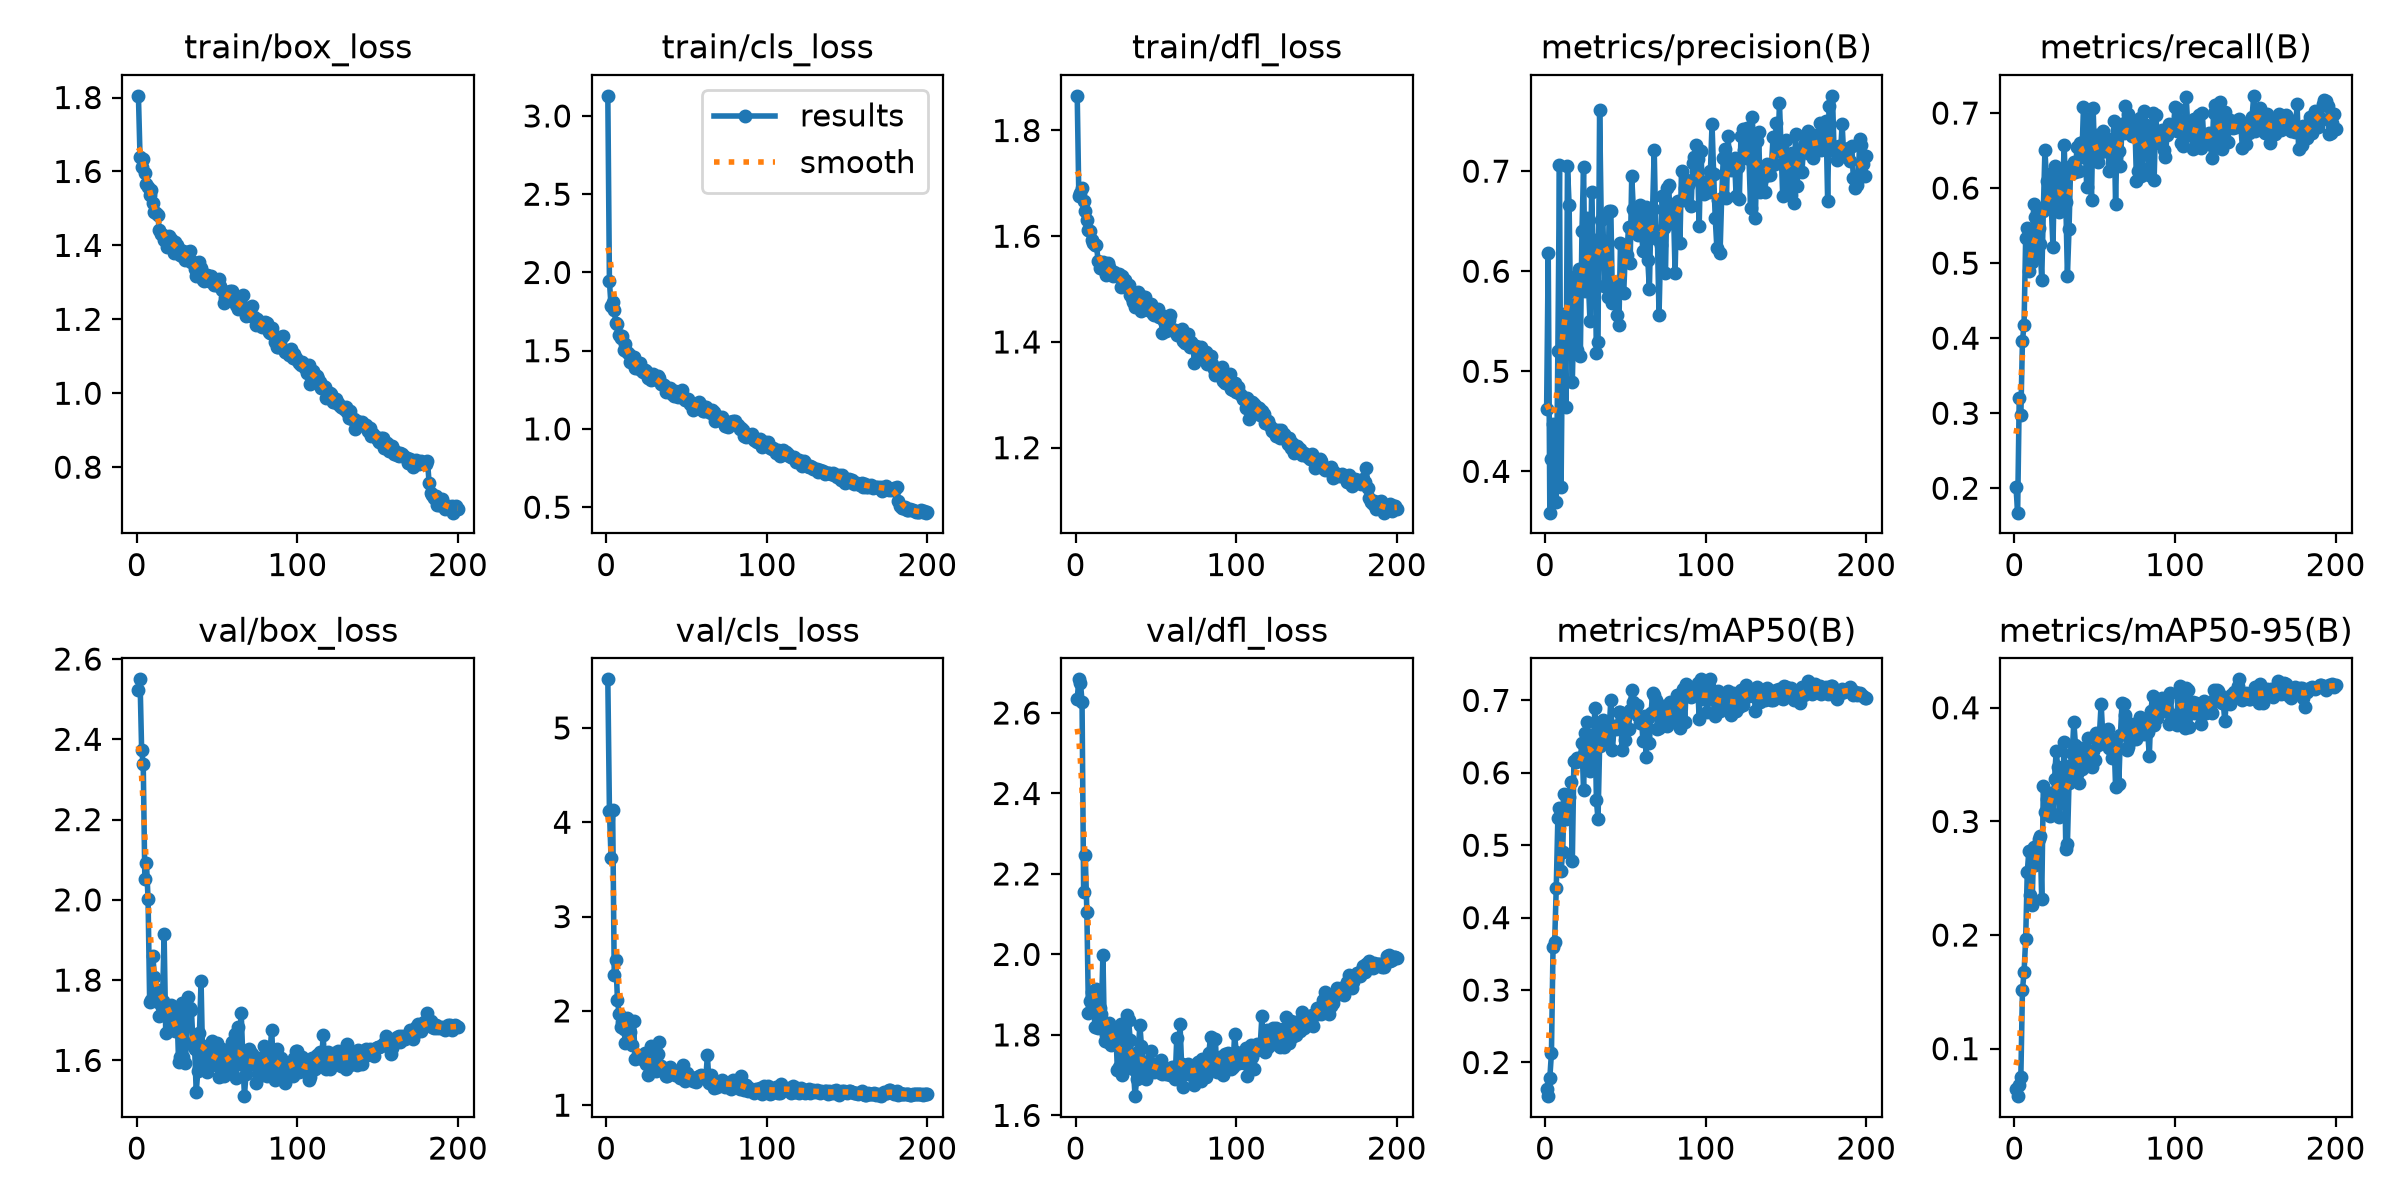

runs\neu_yolov8s_test\confusion_matrix_normalized.png


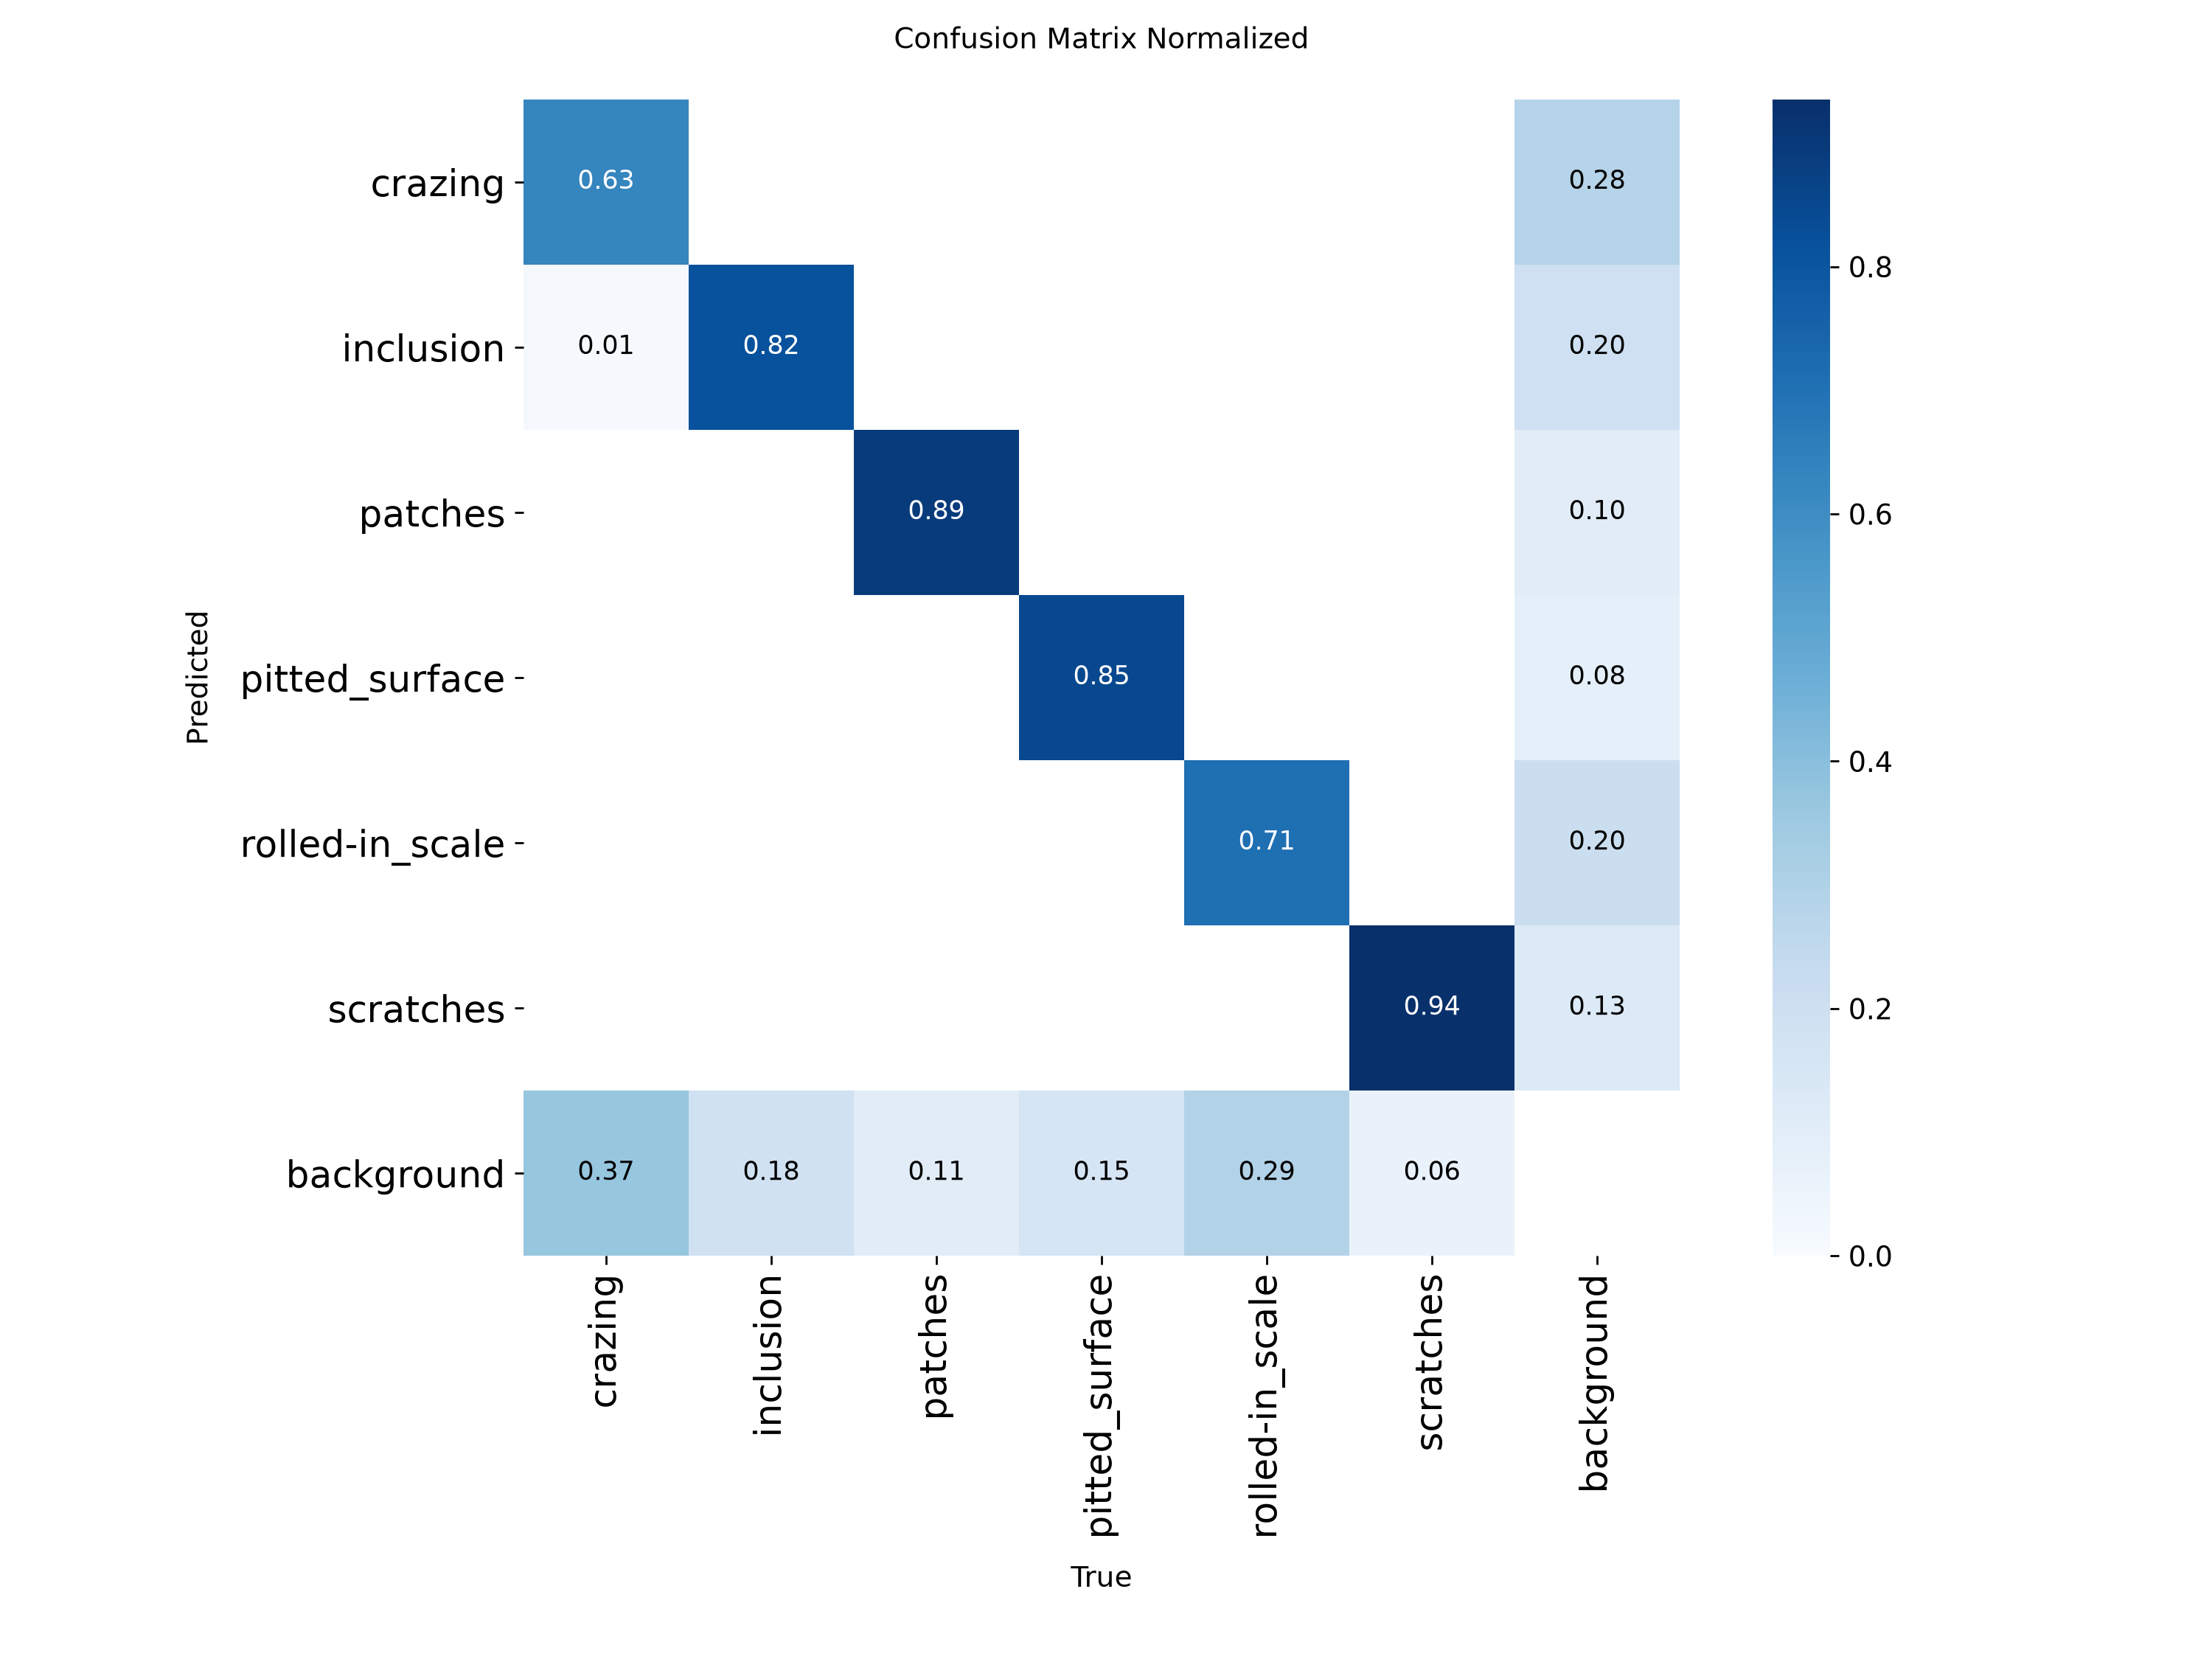

runs\neu_yolov9s\results.png


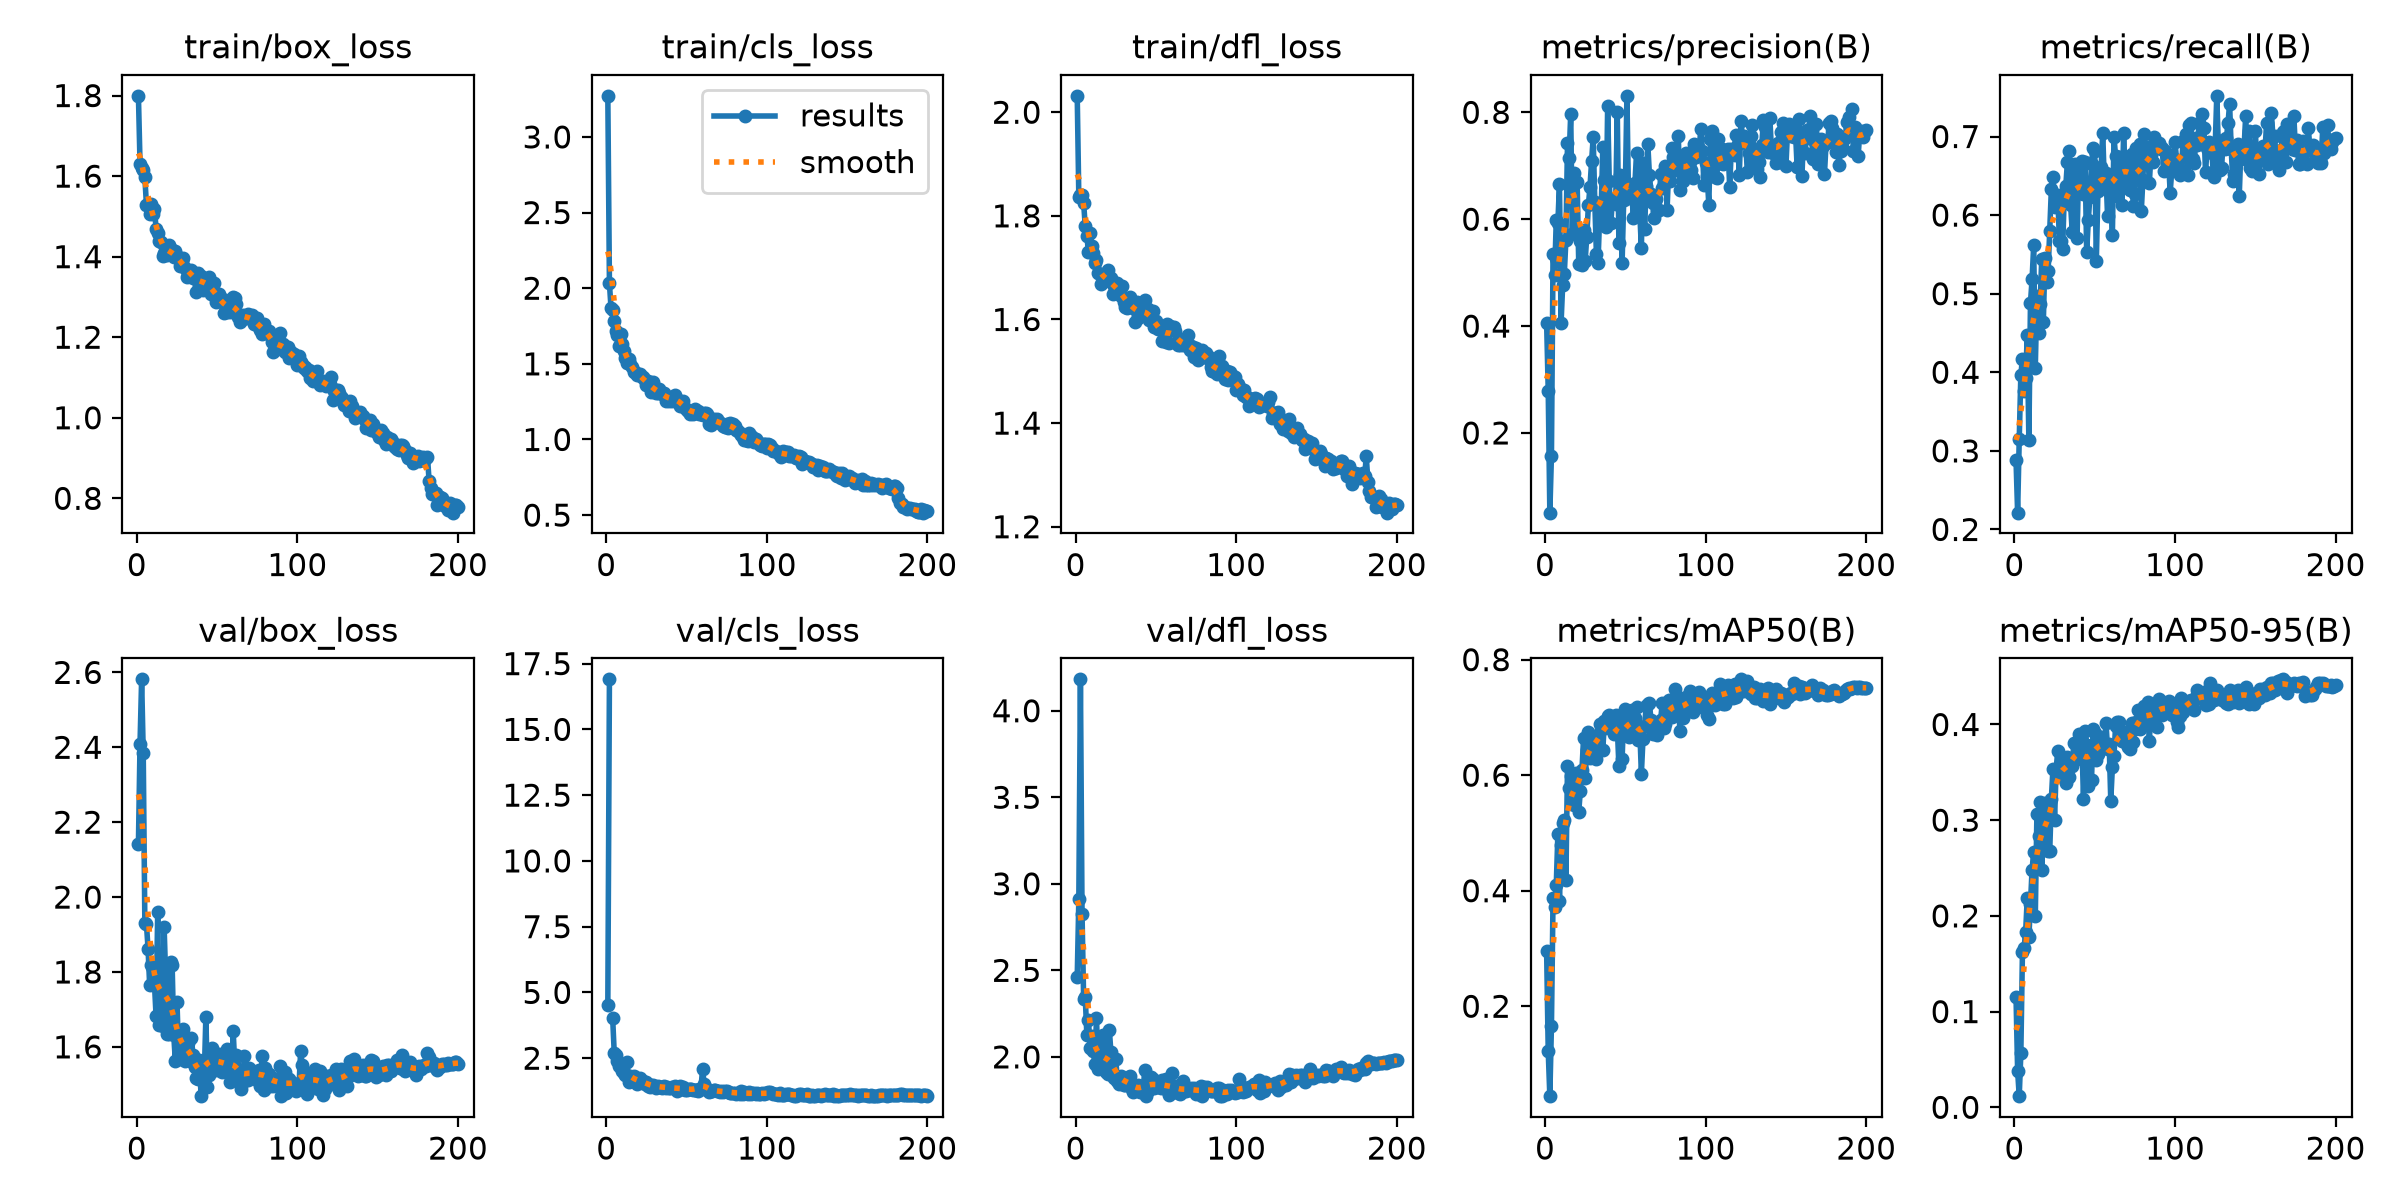

runs\neu_yolov9s_test\confusion_matrix_normalized.png


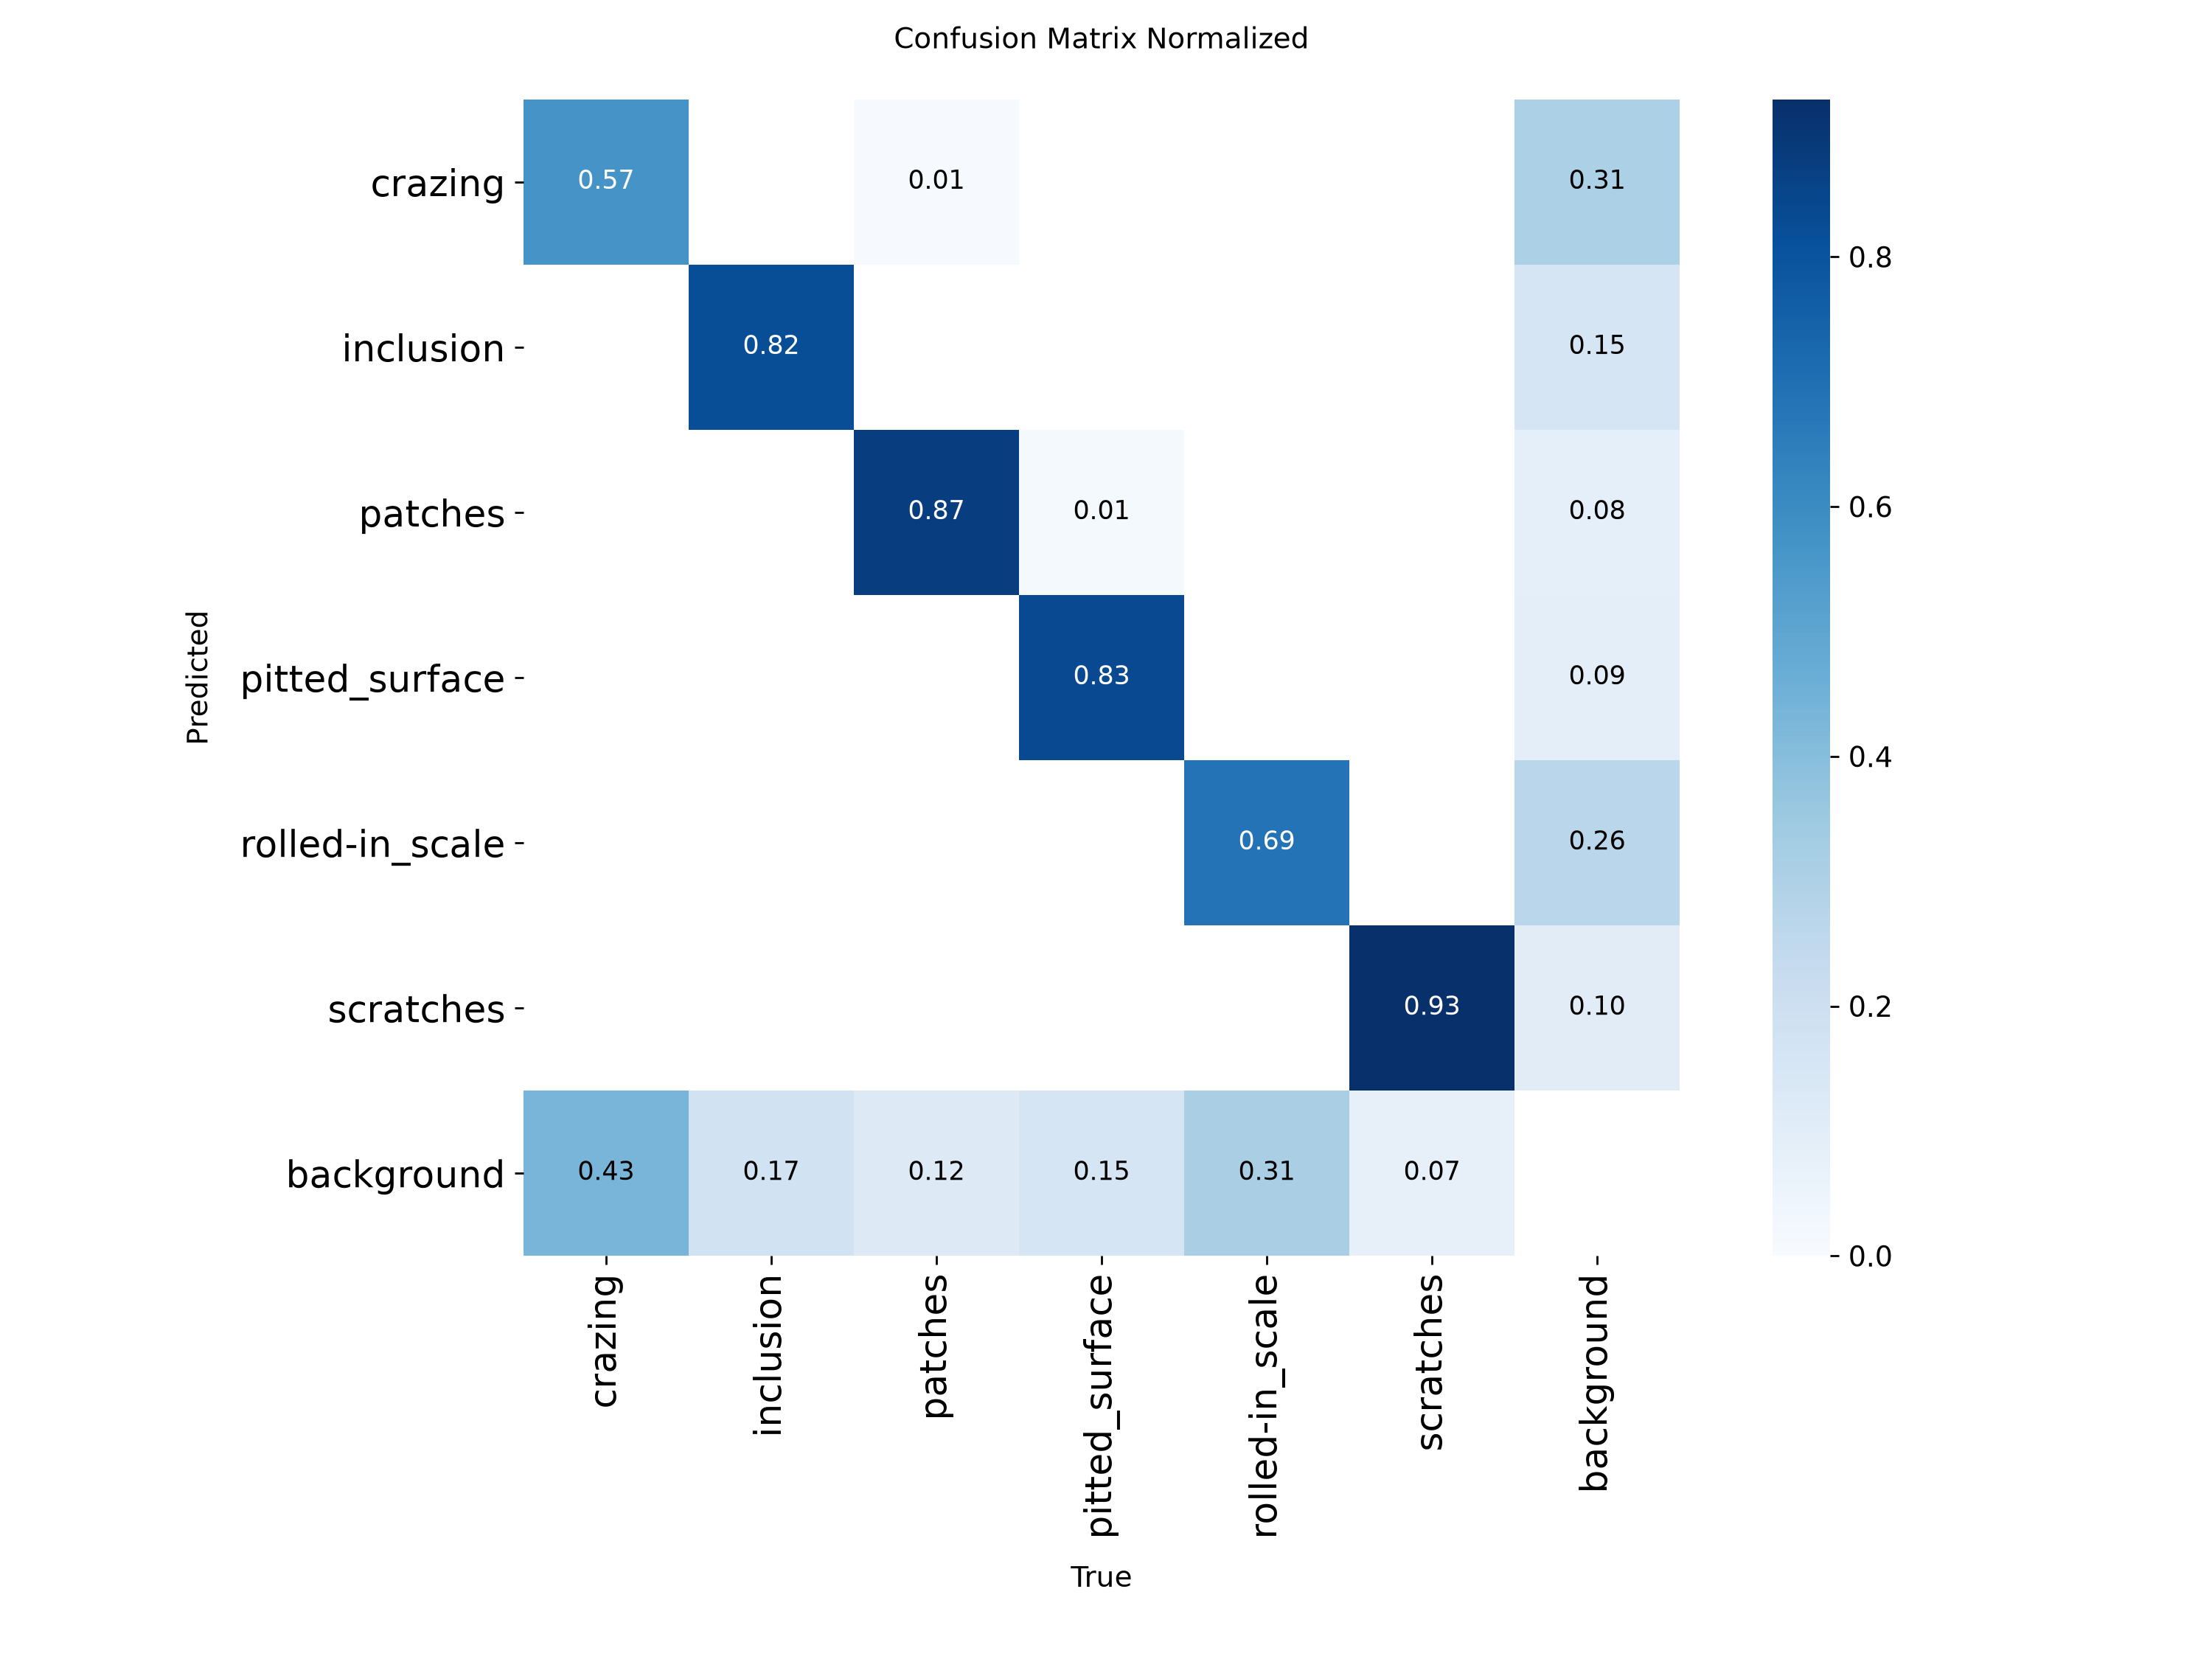

In [ ]:
# Training curves and test confusion matrix per run
for run in df.run:
    for f in (Path("runs", run, "results.png"),
              Path("runs", f"{run}_test", "confusion_matrix_normalized.png")):
        if f.exists():
            print(f)
            display(Image(filename=str(f), width=900))

## 12. Zip results

In [ ]:
out = shutil.make_archive(f"sdf_v2_results_neu", "zip", root_dir=PROJECT_DIR, base_dir="runs")
print("saved", out)

saved c:\Users\Shivapreetham\Desktop\colab_sdf_yolo_v2\colab_sdf_yolo_v2\sdf_v2_results_neu.zip
